<a href="https://colab.research.google.com/github/Kellia855/intro-to-ml_summative/blob/main/copd_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Estimating the Likelihood of a Reported COPD Diagnosis in Adults 50+

**Goal.** COPD is often underdiagnosed because many people never get a breathing test. This project compares traditional machine learning and deep learning models that estimate how likely an adult aged 50 or older is to report a physician diagnosis of COPD, using self-reported demographic, lifestyle and health-history answers. It is intended as a **screening aid** to help prioritise people for clinical testing, not a diagnostic tool.

**What the model predicts.** The target `copd` is 1 if the respondent reports ever being told by a doctor that they have COPD, emphysema or chronic bronchitis (`CHCCOPD3`) and 0 otherwise. The model learns from about 269,000 respondents' answers and returns a probability for a new person. It does not diagnose COPD or forecast future disease, and undiagnosed cases appear as negatives in the data.

**Data.** CDC Behavioral Risk Factor Surveillance System (BRFSS) 2023; https://www.cdc.gov/brfss/annual_data/annual_2023.html


## Part 0. Setup

In [ ]:
import os, json, time, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import loguniform, randint
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score,
                             f1_score, fbeta_score, balanced_accuracy_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import shutil, zipfile, os
zip_path = "/content/drive/MyDrive/ml_project/LLCP2023XPT.zip"
with zipfile.ZipFile(zip_path) as z:
    z.extractall("/content/data")
# the file inside has a trailing space in its name, so find it and rename it
for f in os.listdir("/content/data"):
    if f.strip().upper() == "LLCP2023.XPT":
        os.rename(f"/content/data/{f}", "/content/data/LLCP2023.XPT")

In [ ]:
import numpy as np
import pandas as pd

# ---- Configuration -------------------------------------------------------
RAW_PATH  = "/content/data/LLCP2023.XPT"
OUT_PATH  = "/content/drive/MyDrive/ml_project/brfss_copd_50plus.parquet"
MODEL_DIR = "/content/drive/MyDrive/ml_project/models"

SEED, CHUNK = 42, 50_000
QUICK_RUN, QUICK_FRAC = False, 0.12
TUNE_N, SVM_N, LC_N, PI_N = 60_000, 15_000, 80_000, 15_000
N_ITER = {"logreg": 6, "rf": 6, "hgb": 12}
if QUICK_RUN:
    N_ITER = {"logreg": 3, "rf": 3, "hgb": 4}
SUFFIX = "_quick" if QUICK_RUN else ""
os.makedirs(MODEL_DIR, exist_ok=True)

USE_WANDB     = True
WANDB_PROJECT = "copd-2023"
WANDB_ENTITY  = None


### Experiment tracking with Weights & Biases

Every model run, experiment and tuning search is logged to a [Weights & Biases](https://wandb.ai) project so results can be compared and shared. Runs are organised into groups: `data`, `baselines`, `exp-missing-values`, `exp-imbalance`, `tuning` and `final`. On the first run a login prompt asks for your API key (get it at https://wandb.ai/authorize). Set `USE_WANDB = False` in the configuration to run without logging.

In [ ]:
RUN = None
if USE_WANDB:
    try:
        import wandb
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "wandb"])
        import wandb
    if os.environ.get("WANDB_MODE") != "offline":
        try:
            from google.colab import userdata                       # Colab Secrets
            wandb_key = userdata.get("WANDB_API_KEY")
        except ImportError:
            from kaggle_secrets import UserSecretsClient            # Kaggle Secrets
            wandb_key = UserSecretsClient().get_secret("WANDB_API_KEY")
        wandb.login(key=wandb_key)                                  # key supplied, so no prompt
else:
    wandb = None

def wb_start(name, group, config=None, job_type="train"):
    """Start a W&B run (no-op when USE_WANDB is False)."""
    global RUN
    if not USE_WANDB:
        return None
    RUN = wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY, name=name, group=group, job_type=job_type,
                     config={"seed": SEED, "quick_run": QUICK_RUN, **(config or {})})
    return RUN

def wb_end():
    global RUN
    if RUN is not None:
        wandb.finish()
        RUN = None

def wb_log(d):
    if RUN is not None:
        RUN.log(d)

def wb_summary(d):
    if RUN is not None:
        for k, v in d.items():
            RUN.summary[k] = v

def wb_table(name, frame):
    if RUN is not None:
        RUN.log({name: wandb.Table(dataframe=frame.reset_index())})

def show_fig(name):
    plots_dir = os.path.join(os.path.dirname(MODEL_DIR), "results", "plots")
    os.makedirs(plots_dir, exist_ok=True)
    fig = plt.gcf()
    fig.savefig(os.path.join(plots_dir, f"{name}{SUFFIX}.png"), dpi=150, bbox_inches="tight")
    if RUN is not None:
        RUN.log({name: wandb.Image(fig)})
    plt.show()

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: k-kamikazi (k-kamikazi-african-leadership-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


## Part 1. Data loading and preprocessing

This part loads the raw CDC BRFSS 2023 file (SAS Transport format) plus the 2023 codebook, defines the cohort, recodes survey codes, profiles missing values and saves the cleaned file. If the cleaned file already exists, you can skip this whole part.

### 1.1 Variables

Every name below was checked against the 2023 file. Variable meanings and value codes come from the 2023 codebook (`USCODE23_LLCP_021924.HTML`).

* **Target:** `CHCCOPD3` — ever told you have COPD, emphysema or chronic bronchitis (1 = yes, 2 = no, 7/9 = don't know/refused).
* **Cohort filter:** `_AGEG5YR` — 5-year age category; codes 7–13 are ages 50+, code 14 is don't know/refused.
* **Features:** grouped below. `POORHLTH` is deliberately left out (it is only asked conditionally and may partly reflect COPD symptoms), and race is excluded by default so that any use of it is a documented, justified experiment.

In [ ]:
TARGET = "CHCCOPD3"
AGE    = "_AGEG5YR"

FEATURES = {
    "demographics": ["_AGE80", "SEXVAR", "MARITAL", "EMPLOY1", "EDUCA", "INCOME3", "VETERAN3", "_URBSTAT", "_STATE"],
    "smoking_substances": ["SMOKE100", "_SMOKER3", "SMOKDAY2", "LASTSMK2", "USENOW3", "ALCDAY4", "_DRNKWK2"],
    "health_status": ["GENHLTH", "PHYSHLTH", "MENTHLTH", "_BMI5", "_BMI5CAT", "EXERANY2", "DIFFWALK", "DIFFDRES", "DIFFALON"],
    "comorbidities": ["ASTHMA3", "CVDINFR4", "CVDCRHD4", "CVDSTRK3", "DIABETE4", "BPHIGH6", "TOLDHI3", "ADDEPEV3", "HAVARTH4", "CHCKDNY2"],
    "healthcare_use": ["CHECKUP1", "MEDCOST1", "FLUSHOT7", "PNEUVAC4"],
}
FEATURE_COLS = [c for cols in FEATURES.values() for c in cols]
KEEP = [TARGET, AGE] + FEATURE_COLS
print(len(FEATURE_COLS), "candidate features")

39 candidate features


### 1.2 Load the raw file in chunks

Only the columns we need are kept, and the **raw row count** is recorded while reading, because the assignment requires reporting the dataset size *before* any preprocessing.

In [ ]:
reader = pd.read_sas(RAW_PATH, format="xport", chunksize=CHUNK, encoding="latin-1")
parts, n_raw, n_cols_raw = [], 0, None
for chunk in reader:
    n_cols_raw = chunk.shape[1]
    n_raw += len(chunk)
    parts.append(chunk[KEEP].copy())
raw = pd.concat(parts, ignore_index=True)
del parts

print(f"Raw file: {n_raw:,} rows x {n_cols_raw} columns")
print(f"Kept    : {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Raw file: 433,323 rows x 350 columns
Kept    : 433,323 rows x 41 columns


,CHCCOPD3,_AGEG5YR,_AGE80,SEXVAR,MARITAL,EMPLOY1,EDUCA,INCOME3,VETERAN3,_URBSTAT,_STATE,SMOKE100,_SMOKER3,SMOKDAY2,LASTSMK2,...,DIFFALON,ASTHMA3,CVDINFR4,CVDCRHD4,CVDSTRK3,DIABETE4,BPHIGH6,TOLDHI3,ADDEPEV3,HAVARTH4,CHCKDNY2,CHECKUP1,MEDCOST1,FLUSHOT7,PNEUVAC4
0,2.0,13.0,80.0,2.0,1.0,7.0,5.0,99.0,2.0,1.0,1.0,2.0,4.0,NaN,NaN,...,2.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0
1,2.0,13.0,80.0,2.0,2.0,7.0,5.0,99.0,2.0,1.0,1.0,2.0,4.0,NaN,NaN,...,2.0,2.0,2.0,2.0,2.0,3.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,1.0,1.0
2,2.0,13.0,80.0,2.0,3.0,7.0,4.0,2.0,2.0,1.0,1.0,1.0,3.0,3.0,7.0,...,2.0,1.0,2.0,2.0,2.0,3.0,1.0,1.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0
3,2.0,12.0,78.0,2.0,1.0,7.0,5.0,99.0,2.0,1.0,1.0,2.0,4.0,NaN,NaN,...,2.0,2.0,2.0,2.0,2.0,3.0,3.0,2.0,1.0,1.0,2.0,3.0,2.0,1.0,1.0
4,2.0,12.0,76.0,2.0,3.0,8.0,5.0,7.0,2.0,1.0,1.0,2.0,4.0,NaN,NaN,...,1.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,1.0,1.0,2.0,1.0,2.0,2.0,1.0


### 1.3 Define the cohort

1. Keep respondents with a valid target answer (1 = yes, 2 = no); drop "don't know", "refused" and blank.
2. Keep adults aged 50 and older (`_AGEG5YR` 7–13); drop code 14.

The funnel table documents how many rows survive each step.

In [ ]:
funnel = [("Raw BRFSS 2023 records", len(raw))]

df = raw[raw[TARGET].isin([1, 2])].copy()
funnel.append(("Valid COPD answer (1 or 2)", len(df)))

df = df[df[AGE].between(7, 13)].copy()
funnel.append(("Adults 50+ (_AGEG5YR 7-13)", len(df)))

df["copd"] = (df[TARGET] == 1).astype(int)
funnel_df = pd.DataFrame(funnel, columns=["step", "rows"])
funnel_df["dropped"] = funnel_df["rows"].diff().fillna(0).astype(int)
display(funnel_df)

prev = df["copd"].mean()
print(f"COPD prevalence in cohort: {prev:.2%}  ({df['copd'].sum():,} positives, imbalance about 1:{(1-prev)/prev:.1f})")

,step,rows,dropped
0,Raw BRFSS 2023 records,433323,0
1,Valid COPD answer (1 or 2),431257,-2066
2,Adults 50+ (_AGEG5YR 7-13),269252,-162005


COPD prevalence in cohort: 10.56%  (28,432 positives, imbalance about 1:8.5)


### 1.4 Recode special values

BRFSS stores "don't know", "refused" and "none" as numeric codes that would be read as real values if left in place. Each rule below follows the 2023 codebook:

* Yes/no questions: 1 = yes, 2 = no, 7 and 9 = don't know/refused → missing.
* Days variables (`PHYSHLTH`, `MENTHLTH`): 88 = none → 0; 77 and 99 → missing.
* `ALCDAY4`: 101–199 = days per week, 201–299 = days per month, 888 = no drinks, 777/999 → missing. Converted to **drinking days per month**.
* `_DRNKWK2`: 99900 = missing; the stored value has two implied decimals, and a true zero is stored by SAS as a tiny denormal number (about 5e-79), which is snapped to exactly 0.
* `_BMI5`: two implied decimals (divide by 100).
* Ordinal/nominal categoricals: refusal codes → missing.
* Blank values on `SMOKDAY2`, `LASTSMK2` and `USENOW3` are *structural* (the question was skipped by design) and are kept as missing for now. Whether to impute, add indicator columns, or use an "not applicable" category is a modelling decision to document and compare.

In [ ]:
def recode(d):
    d = d.copy()

    yes_no = ["SMOKE100", "EXERANY2", "DIFFWALK", "DIFFDRES", "DIFFALON", "VETERAN3",
              "ASTHMA3", "CVDINFR4", "CVDCRHD4", "CVDSTRK3", "TOLDHI3", "ADDEPEV3",
              "HAVARTH4", "CHCKDNY2", "MEDCOST1", "FLUSHOT7", "PNEUVAC4"]
    for c in yes_no:
        d[c] = d[c].map({1: 1, 2: 0})            # 7, 9, blank -> NaN

    d["is_female"] = (d["SEXVAR"] == 2).astype(int)

    # days variables
    for c in ["PHYSHLTH", "MENTHLTH"]:
        d[c] = d[c].replace({88: 0, 77: np.nan, 99: np.nan})

    # alcohol: drinking days per month
    a = d["ALCDAY4"]
    d["alc_days_month"] = np.select(
        [a == 888, a.between(101, 199), a.between(201, 299)],
        [0, (a - 100) * 30 / 7, a - 200],
        default=np.nan,
    )
    # SAS XPT stores a true 0 as a denormal (~5e-79); snap values that small to exactly 0
    drinks = d["_DRNKWK2"].replace(99900, np.nan) / 100
    d["alc_drinks_week"] = drinks.mask(drinks.abs() < 1e-6, 0)

    d["bmi"] = d["_BMI5"] / 100

    # categorical / ordinal codes with refusal values
    d["MARITAL"] = d["MARITAL"].replace({9: np.nan})
    d["EMPLOY1"] = d["EMPLOY1"].replace({9: np.nan})
    d["EDUCA"]   = d["EDUCA"].replace({9: np.nan})
    d["INCOME3"] = d["INCOME3"].replace({77: np.nan, 99: np.nan})
    d["GENHLTH"] = d["GENHLTH"].replace({7: np.nan, 9: np.nan})
    d["_SMOKER3"] = d["_SMOKER3"].replace({9: np.nan})
    d["SMOKDAY2"] = d["SMOKDAY2"].replace({7: np.nan, 9: np.nan})
    d["LASTSMK2"] = d["LASTSMK2"].replace({77: np.nan, 99: np.nan})
    d["USENOW3"]  = d["USENOW3"].replace({7: np.nan, 9: np.nan})
    d["DIABETE4"] = d["DIABETE4"].replace({7: np.nan, 9: np.nan})   # 1 yes, 2 yes (pregnancy only), 3 no, 4 prediabetes
    d["BPHIGH6"]  = d["BPHIGH6"].replace({7: np.nan, 9: np.nan})    # 1 yes, 2 yes (pregnancy only), 3 no, 4 borderline
    d["CHECKUP1"] = d["CHECKUP1"].replace({7: np.nan, 9: np.nan})   # 8 = never (kept as a real answer)

    d = d.drop(columns=["SEXVAR", "ALCDAY4", "_DRNKWK2", "_BMI5"])
    return d

clean = recode(df.drop(columns=[TARGET]))
print(clean.shape)
clean.head()

(269252, 41)


,_AGEG5YR,_AGE80,MARITAL,EMPLOY1,EDUCA,INCOME3,VETERAN3,_URBSTAT,_STATE,SMOKE100,_SMOKER3,SMOKDAY2,LASTSMK2,USENOW3,GENHLTH,...,DIABETE4,BPHIGH6,TOLDHI3,ADDEPEV3,HAVARTH4,CHCKDNY2,CHECKUP1,MEDCOST1,FLUSHOT7,PNEUVAC4,copd,is_female,alc_days_month,alc_drinks_week,bmi
0,13.0,80.0,1.0,7.0,5.0,NaN,0.0,1.0,1.0,0.0,4.0,NaN,NaN,3.0,2.0,...,1.0,1.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0,1,0.0,0.00,30.47
1,13.0,80.0,2.0,7.0,5.0,NaN,0.0,1.0,1.0,0.0,4.0,NaN,NaN,3.0,2.0,...,3.0,1.0,1.0,1.0,1.0,0.0,2.0,0.0,1.0,1.0,0,1,0.0,0.00,28.56
2,13.0,80.0,3.0,7.0,4.0,2.0,0.0,1.0,1.0,1.0,3.0,3.0,7.0,3.0,4.0,...,3.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0,1,0.0,0.00,22.31
3,12.0,78.0,1.0,7.0,5.0,NaN,0.0,1.0,1.0,0.0,4.0,NaN,NaN,3.0,2.0,...,3.0,3.0,0.0,1.0,1.0,0.0,3.0,0.0,1.0,1.0,0,1,0.0,0.00,27.44
4,12.0,76.0,3.0,8.0,5.0,7.0,0.0,1.0,1.0,0.0,4.0,NaN,NaN,2.0,4.0,...,1.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0,1,2.0,0.47,25.85


### 1.5 Sanity checks and missing-value profile

Quick checks that the recoding behaved as intended (value ranges and category counts), followed by the share of missing values per column. Columns with a lot of missingness need an explicit strategy in the modelling notebooks.

In [ ]:
print(clean[["_AGE80", "bmi", "PHYSHLTH", "MENTHLTH", "alc_days_month", "alc_drinks_week"]].describe().round(2))
print()
for c in ["GENHLTH", "_SMOKER3", "DIABETE4", "BPHIGH6", "_AGEG5YR"]:
    print(c, clean[c].value_counts(dropna=False).sort_index().to_dict())

          _AGE80        bmi   PHYSHLTH   MENTHLTH  alc_days_month  alc_drinks_week
count  269252.00  248049.00  261616.00  264062.00       252517.00        251138.00
mean       67.12      28.50       5.16       3.39            5.14             2.54
std         9.18       6.24       9.60       7.68            8.69             7.32
min        50.00      12.02       0.00       0.00            0.00             0.00
25%        60.00      24.33       0.00       0.00            0.00             0.00
50%        67.00      27.44       0.00       0.00            0.00             0.00
75%        75.00      31.57       5.00       2.00            5.00             2.00
max        80.00      99.82      30.00      30.00           30.00           532.00

GENHLTH {1.0: 33173, 2.0: 86385, 3.0: 89949, 4.0: 42925, 5.0: 15981, nan: 839}
_SMOKER3 {1.0: 19931, 2.0: 6956, 3.0: 83088, 4.0: 146445, nan: 12832}
DIABETE4 {1.0: 51634, 2.0: 1184, 3.0: 207986, 4.0: 8068, nan: 380}
BPHIGH6 {1.0: 143903, 2.0: 860, 3.0:

In [ ]:
miss = (clean.isna().mean() * 100).round(2).sort_values(ascending=False)
display(miss[miss > 0].to_frame("% missing"))

print("\nMissingness by COPD status (columns with the largest gap):")
gap = (clean.groupby("copd").apply(lambda g: g.isna().mean() * 100).T)
gap["diff"] = (gap[1] - gap[0]).abs()
display(gap.sort_values("diff", ascending=False).head(8).round(2))

,% missing
LASTSMK2,86.18
SMOKDAY2,59.16
INCOME3,20.37
PNEUVAC4,9.81
_BMI5CAT,7.87
bmi,7.87
alc_drinks_week,6.73
FLUSHOT7,6.35
alc_days_month,6.22
TOLDHI3,5.88



Missingness by COPD status (columns with the largest gap):


copd,0,1,diff
SMOKDAY2,62.97,26.87,36.10
LASTSMK2,87.03,78.97,8.06
CVDCRHD4,1.01,2.85,1.84
PNEUVAC4,9.99,8.23,1.76
PHYSHLTH,2.66,4.30,1.64
TOLDHI3,5.75,6.96,1.21
MENTHLTH,1.82,2.85,1.03
_BMI5CAT,7.98,7.02,0.96


### 1.6 Save the cleaned cohort

The saved Parquet file loads in seconds and keeps this notebook independent from the 1.2 GB raw file. Modelling notebooks should apply the stratified train/validation/test split themselves, with `SEED` fixed, and fit all imputers, scalers and encoders on the training set only to avoid leakage.

In [ ]:
clean.to_parquet(OUT_PATH, index=False)
print("Saved", OUT_PATH, clean.shape)

Saved /content/drive/MyDrive/ml_project/brfss_copd_50plus.parquet (269252, 41)


In [ ]:
import pandas as pd
df = pd.read_parquet("/content/drive/MyDrive/ml_project/brfss_copd_50plus.parquet")
print(df.shape)
print(df["copd"].value_counts())

(269252, 41)
copd
0    240820
1     28432
Name: count, dtype: int64


## Part 2. Traditional machine learning(Scikit-learn)
This part trains and compares traditional models on the cleaned cohort from Part 1


### 2.1 Load the cleaned cohort

Part 1 produced one row per respondent aged 50+ with a valid COPD answer. The column `copd` is the target (1 = reports a COPD diagnosis). Two columns, `_AGEG5YR` and `_BMI5CAT`, duplicate `_AGE80` and `bmi`, so they are kept only as *metadata* for the subgroup analysis and are not used as features.

`CHECKUP1` uses code 8 for "never"; it is recoded to 5 so the variable is a single ordinal scale (1 = within the past year ... 5 = never).

In [ ]:
df = pd.read_parquet(OUT_PATH)
if QUICK_RUN:
    df = (df.groupby("copd", group_keys=False)
            .sample(frac=QUICK_FRAC, random_state=SEED).sort_index())
df = df.reset_index(drop=True)
df["CHECKUP1"] = df["CHECKUP1"].replace(8, 5)

print(df.shape, f"| positive rate {df['copd'].mean():.2%}")

(269252, 41) | positive rate 10.56%


### 2.2 Feature groups

Every feature is assigned to a type so that each gets the right treatment:

* **Continuous** (`bmi`, drinks, days of poor health): clipped at the 1st/99th percentile (learned on training data), median-imputed, scaled.
* **Binary and ordinal** (yes/no answers coded 0/1, health and income scales): median-imputed (the mode for binary), scaled.
* **Nominal** (marital status, employment, diabetes status, smoker status, state, ...): one-hot encoded; rare categories grouped.

In [ ]:
TARGET = "copd"
CONT    = ["bmi", "alc_days_month", "alc_drinks_week", "PHYSHLTH", "MENTHLTH", "_AGE80"]
BINARY  = ["is_female", "SMOKE100", "EXERANY2", "DIFFWALK", "DIFFDRES", "DIFFALON", "VETERAN3", "ASTHMA3",
           "CVDINFR4", "CVDCRHD4", "CVDSTRK3", "TOLDHI3", "ADDEPEV3", "HAVARTH4", "CHCKDNY2",
           "MEDCOST1", "FLUSHOT7", "PNEUVAC4"]
ORDINAL = ["GENHLTH", "EDUCA", "INCOME3", "CHECKUP1"]
NOMINAL = ["MARITAL", "EMPLOY1", "DIABETE4", "BPHIGH6", "_SMOKER3", "SMOKDAY2", "LASTSMK2", "USENOW3",
           "_URBSTAT", "_STATE"]
META    = ["_AGEG5YR", "_BMI5CAT"]
ALL_FEATURES = CONT + BINARY + ORDINAL + NOMINAL

missing = [c for c in ALL_FEATURES + META if c not in df.columns]
assert not missing, missing
X, y = df[ALL_FEATURES], df[TARGET].values
print(len(ALL_FEATURES), "features")

38 features


### 2.3 Train / validation / test split

A stratified 70 / 15 / 15 split keeps the 10.6% positive rate in all three parts. The **training set** fits models and preprocessing, the **validation set** is used for model selection and for choosing decision thresholds, and the **test set** is touched only for the final evaluation. The row indices are saved at the end so the deep learning part (Part 3) can reuse the identical split.

BRFSS respondents are independent survey participants (there is no patient identifier and no repeated measurement), so a random split is appropriate.

In [ ]:
idx = np.arange(len(df))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
idx_val, idx_test  = train_test_split(idx_tmp, test_size=0.50, stratify=y[idx_tmp], random_state=SEED)

X_train, y_train = X.iloc[idx_train], y[idx_train]
X_val,   y_val   = X.iloc[idx_val],   y[idx_val]
X_test,  y_test  = X.iloc[idx_test],  y[idx_test]

pd.DataFrame({"rows": [len(idx_train), len(idx_val), len(idx_test)],
              "positives": [y_train.sum(), y_val.sum(), y_test.sum()],
              "positive rate": [y_train.mean(), y_val.mean(), y_test.mean()]},
             index=["train", "validation", "test"]).round(4)

,rows,positives,positive rate
train,188476,19902,0.1056
validation,40388,4265,0.1056
test,40388,4265,0.1056


### 2.4 Preprocessing pipelines

All preprocessing lives **inside** scikit-learn pipelines, so imputers, scalers, encoders and the clipping limits are fitted on training rows only (also inside each cross-validation fold). This prevents information from the validation or test data leaking into training.

`make_preprocessor` supports two missing-value strategies, compared in section 8:

* `"simple"`: median (numeric) or most-frequent (categorical) imputation.
* `"indicator"`: the same numeric imputation **plus missing-indicator columns**, and an explicit "missing / not asked" category for nominal variables. This matters here because some blanks are structural (for example `SMOKDAY2` is blank for people who never smoked), so *being missing carries information*.

In [ ]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip each column to the [lower, upper] quantiles learned on the training data."""
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_ = np.nanquantile(X, self.lower, axis=0)
        self.hi_ = np.nanquantile(X, self.upper, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

def make_preprocessor(cols, strategy="indicator", scale=True):
    ind  = strategy == "indicator"
    cont = [c for c in CONT if c in cols]
    other = [c for c in BINARY + ORDINAL if c in cols]
    nom  = [c for c in NOMINAL if c in cols]

    def num_steps(winsor):
        steps = [("winsor", Winsorizer())] if winsor else []
        steps.append(("impute", SimpleImputer(strategy="median", add_indicator=ind)))
        if scale:
            steps.append(("scale", StandardScaler()))
        return Pipeline(steps)

    nom_imp = SimpleImputer(strategy="constant", fill_value=-1) if ind else SimpleImputer(strategy="most_frequent")
    nom_pipe = Pipeline([("impute", nom_imp),
                         ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=200,
                                               sparse_output=False, dtype=np.float32))])
    parts = []
    if cont:  parts.append(("cont", num_steps(True), cont))
    if other: parts.append(("other", num_steps(False), other))
    if nom:   parts.append(("nom", nom_pipe, nom))
    return ColumnTransformer(parts, remainder="drop")

DEFAULTS = {
    "logreg": dict(C=1.0, class_weight="balanced"),
    "rf":     dict(n_estimators=150, max_depth=None, min_samples_leaf=5, max_features="sqrt",
                   class_weight="balanced_subsample"),
    "hgb":    dict(learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=50, l2_regularization=1.0,
                   class_weight="balanced"),
    "svm":    dict(C=1.0, class_weight="balanced"),
}

def build(name, cols=ALL_FEATURES, strategy="indicator", **params):
    p = {**DEFAULTS[name], **params}
    if name == "logreg":
        clf, scale = LogisticRegression(max_iter=2000, **p), True
    elif name == "rf":
        clf, scale = RandomForestClassifier(n_jobs=-1, random_state=SEED, **p), False
    elif name == "hgb":
        clf, scale = HistGradientBoostingClassifier(max_iter=500, early_stopping=True, validation_fraction=0.1,
                                                    n_iter_no_change=20, random_state=SEED, **p), False
    elif name == "svm":
        clf, scale = SVC(kernel="rbf", gamma="scale", **p), True
    return Pipeline([("prep", make_preprocessor(cols, strategy, scale)), ("clf", clf)])

print(build("logreg"))

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cont',
                                                  Pipeline(steps=[('winsor',
                                                                   Winsorizer()),
                                                                  ('impute',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['bmi', 'alc_days_month',
                                                   'alc_drinks_week',
                                                   'PHYSHLTH', 'MENTHLTH',
                                                   '_AGE80']),
                              

### 2.5 Evaluation helpers

For each model we report threshold-free metrics (ROC-AUC, PR-AUC) and, at a decision threshold, recall, precision, F1, F2 and balanced accuracy. **Thresholds are always chosen on the validation set** (the one that maximises F2) and then applied unchanged to the test set.

In [ ]:
def get_scores(model, X_):
    return model.predict_proba(X_)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_)

def best_threshold(y_true, s, beta=2.0):
    prec, rec, thr = precision_recall_curve(y_true, s)
    f = (1 + beta**2) * prec * rec / (beta**2 * prec + rec + 1e-12)
    return thr[np.nanargmax(f[:-1])]

def metrics(y_true, s, thr):
    pred = (s >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y_true, s), "PR-AUC": average_precision_score(y_true, s),
            "threshold": thr, "recall": recall_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred), "F2": fbeta_score(y_true, pred, beta=2),
            "balanced acc": balanced_accuracy_score(y_true, pred),
            "flagged %": pred.mean() * 100}

def stratified_sample(X_, y_, n, seed=SEED):
    if n >= len(X_):
        return X_, y_
    sel, _ = train_test_split(np.arange(len(X_)), train_size=n, stratify=y_, random_state=seed)
    return X_.iloc[sel], y_[sel]

### 2.6 Baseline and candidate models

Logistic Regression is the **baseline**: a simple, interpretable linear model that every other model has to beat to justify its extra complexity. Random Forest, Gradient Boosting and an RBF-kernel SVM are the **candidate models**. All four are trained once with sensible default settings and class weighting for the imbalance, then compared on the validation set. The best candidates are tuned in section 2.9.

Each model has its own cell below. They share one helper that fits the model, picks its F2-optimal threshold on the validation set, records the metrics and logs the run to Weights & Biases (group `initial-models`).

In [ ]:
results, val_scores, fitted = [], {}, {}

def run_model(label, model, X_fit, y_fit, role="candidate"):
    wb_start(label, "initial-models", {"model": label, "role": role,
                                       "train_rows": len(X_fit), "n_features": len(ALL_FEATURES)})
    t0 = time.time()
    model.fit(X_fit, y_fit)
    s = get_scores(model, X_val)
    thr = best_threshold(y_val, s)
    res = {"model": label, "role": role, **metrics(y_val, s, thr), "fit time (s)": time.time() - t0}
    results.append(res); val_scores[label] = s; fitted[label] = model
    print(f"{label:28s} PR-AUC {res['PR-AUC']:.3f}  ROC-AUC {res['ROC-AUC']:.3f}  ({res['fit time (s)']:.0f}s)")
    wb_log({f"val/{k}": v for k, v in res.items() if k not in ("model", "role")}); wb_end()

#### Baseline: Logistic Regression
A linear model that estimates the probability of COPD as a weighted sum of the features. It is fast, hard to overfit and easy to interpret, which makes it the standard reference point. `class_weight="balanced"` gives the rare positive class more weight, and `C=1.0` applies moderate regularisation.

In [ ]:
run_model("Logistic Regression", build("logreg"), X_train, y_train, role="baseline")

Logistic Regression          PR-AUC 0.477  ROC-AUC 0.858  (13s)


val/F1,▁
val/F2,▁
val/PR-AUC,▁
val/ROC-AUC,▁
val/balanced acc,▁
val/fit time (s),▁
val/flagged %,▁
val/precision,▁
val/recall,▁
val/threshold,▁
val/F1,0.43709


#### Candidate: Random Forest
Many decision trees trained on random subsets of rows and features, with their votes averaged. It captures non-linear effects and interactions (for example, smoking combined with asthma) that a linear model cannot. `min_samples_leaf=5` and `class_weight="balanced_subsample"` limit overfitting and handle the imbalance.

In [ ]:
run_model("Random Forest", build("rf"), X_train, y_train)

Random Forest                PR-AUC 0.470  ROC-AUC 0.856  (67s)


val/F1,▁
val/F2,▁
val/PR-AUC,▁
val/ROC-AUC,▁
val/balanced acc,▁
val/fit time (s),▁
val/flagged %,▁
val/precision,▁
val/recall,▁
val/threshold,▁
val/F1,0.43244


#### Candidate: Histogram Gradient Boosting
Trees built one after another, each correcting the errors of the previous ones. It is usually the strongest traditional method on tabular data and is fast on large datasets. Early stopping and L2 regularisation limit overfitting, and class weights handle the imbalance.

In [ ]:
run_model("Hist Gradient Boosting", build("hgb"), X_train, y_train)

Hist Gradient Boosting       PR-AUC 0.488  ROC-AUC 0.862  (38s)


val/F1,▁
val/F2,▁
val/PR-AUC,▁
val/ROC-AUC,▁
val/balanced acc,▁
val/fit time (s),▁
val/flagged %,▁
val/precision,▁
val/recall,▁
val/threshold,▁
val/F1,0.41643


#### Candidate: Support Vector Machine (RBF kernel)
Finds a boundary that separates the classes with the widest margin, using a non-linear kernel. Training time grows quickly with the number of rows, so it is trained on a stratified subsample (`SVM_N` rows) instead of the full training set. This is a documented compromise and should be stated in the report.

In [ ]:
Xs, ys = stratified_sample(X_train, y_train, SVM_N)
run_model("SVM (RBF, subsample)", build("svm"), Xs, ys)

SVM (RBF, subsample)         PR-AUC 0.390  ROC-AUC 0.829  (73s)


val/F1,▁
val/F2,▁
val/PR-AUC,▁
val/ROC-AUC,▁
val/balanced acc,▁
val/fit time (s),▁
val/flagged %,▁
val/precision,▁
val/recall,▁
val/threshold,▁
val/F1,0.38358


In [ ]:
initial_df = pd.DataFrame(results).set_index("model").round(3).sort_values("PR-AUC", ascending=False)
initial_df

,role,ROC-AUC,PR-AUC,threshold,recall,precision,F1,F2,balanced acc,flagged %,fit time (s)
model,,,,,,,,,,,
Hist Gradient Boosting,candidate,0.862,0.488,0.465,0.810,0.280,0.416,0.588,0.782,30.502,38.483
Logistic Regression,baseline,0.858,0.477,0.531,0.752,0.308,0.437,0.584,0.776,25.785,12.707
Random Forest,candidate,0.856,0.470,0.378,0.757,0.303,0.432,0.582,0.776,26.416,67.477
"SVM (RBF, subsample)",candidate,0.829,0.390,-0.429,0.772,0.255,0.384,0.550,0.753,31.965,72.828


**Interpretation:** Gradient boosting is the best of the four on validation, but only slightly: PR-AUC 0.488 against 0.477 for logistic regression and ROC-AUC 0.862 against 0.858. Random forest (0.470 / 0.856) slightly trails the baseline. The SVM is clearly worst (0.390 / 0.829), though it was trained on only 15,000 rows so it is not a like-for-like comparison. Boosting costs about three times the fit time of logistic regression (38 s against 13 s) for a gain of about one PR-AUC point so the benefit is real but small. Because the linear baseline comes so close to the tree models, most of the signal looks additive (smoking, asthma, general health, age). Any interactions such as smoking combined with asthma, add only a little on top of that.

### 2.7 Experiment A: missing-value strategy

The same two models are trained with `"simple"` imputation and with `"indicator"` handling (missing-indicator columns and an explicit "missing/not asked" category), and compared on the validation set. If the indicator version is better, the *missingness pattern itself* is informative.

In [ ]:
rows = []
for name in ["logreg", "hgb"]:
    for strat in ["simple", "indicator"]:
        wb_start(f"{name}-{strat}", "exp-missing-values", {"model": name, "strategy": strat})
        m = build(name, strategy=strat).fit(X_train, y_train)
        s = get_scores(m, X_val)
        rows.append({"model": name, "strategy": strat,
                     "ROC-AUC": roc_auc_score(y_val, s), "PR-AUC": average_precision_score(y_val, s)})
        wb_log({"val/ROC-AUC": rows[-1]["ROC-AUC"], "val/PR-AUC": rows[-1]["PR-AUC"]}); wb_end()
missing_df = pd.DataFrame(rows).round(4)
missing_df

val/PR-AUC,▁
val/ROC-AUC,▁
val/PR-AUC,0.4725
val/ROC-AUC,0.85518


val/PR-AUC,▁
val/ROC-AUC,▁
val/PR-AUC,0.47717
val/ROC-AUC,0.85768


val/PR-AUC,▁
val/ROC-AUC,▁
val/PR-AUC,0.48373
val/ROC-AUC,0.85841


val/PR-AUC,▁
val/ROC-AUC,▁
val/PR-AUC,0.48832
val/ROC-AUC,0.86181


,model,strategy,ROC-AUC,PR-AUC
0,logreg,simple,0.8552,0.4725
1,logreg,indicator,0.8577,0.4772
2,hgb,simple,0.8584,0.4837
3,hgb,indicator,0.8618,0.4883


**Interpretation:** Indicators and a “missing / not asked” category help both models by a small consistent amount. For logistic regression, PR-AUC goes from 0.4725 to 0.4772 and ROC-AUC from 0.8552 to 0.8577. For boosting, PR-AUC goes from 0.4837 to 0.4883 and ROC-AUC from 0.8584 to 0.8618. This fits the structural missingness from Part 1: SMOKDAY2 is blank for 63% of non-COPD respondents but only 27% of COPD respondents, because never-smokers skip the question. A blank is therefore a proxy for “never smoked”. The gain is modest because SMOKE100 and _SMOKER3 already encode most of that information.

### 2.8 Experiment B: handling class imbalance

Gradient boosting is trained without weights and with balanced class weights. Threshold-free metrics change little, but the *default 0.5 threshold* behaves very differently, which is why the threshold is tuned on the validation set.

In [ ]:
rows = []
for cw in [None, "balanced"]:
    wb_start(f"hgb-class_weight-{cw}", "exp-imbalance", {"model": "hgb", "class_weight": str(cw)})
    m = build("hgb", class_weight=cw).fit(X_train, y_train)
    s = get_scores(m, X_val)
    thr = best_threshold(y_val, s)
    at05, atopt = metrics(y_val, s, 0.5), metrics(y_val, s, thr)
    rows.append({"class_weight": str(cw), "ROC-AUC": at05["ROC-AUC"], "PR-AUC": at05["PR-AUC"],
                 "recall@0.5": at05["recall"], "precision@0.5": at05["precision"],
                 "tuned thr": thr, "recall@tuned": atopt["recall"], "precision@tuned": atopt["precision"]})
    wb_log({k: v for k, v in rows[-1].items() if k != "class_weight"}); wb_end()
pd.DataFrame(rows).round(3)

wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


PR-AUC,▁
ROC-AUC,▁
precision@0.5,▁
precision@tuned,▁
recall@0.5,▁
recall@tuned,▁
tuned thr,▁
PR-AUC,0.49115
ROC-AUC,0.86214
precision@0.5,0.6429
precision@tuned,0.29561


PR-AUC,▁
ROC-AUC,▁
precision@0.5,▁
precision@tuned,▁
recall@0.5,▁
recall@tuned,▁
tuned thr,▁
PR-AUC,0.48832
ROC-AUC,0.86181
precision@0.5,0.29408
precision@tuned,0.2803


,class_weight,ROC-AUC,PR-AUC,recall@0.5,precision@0.5,tuned thr,recall@tuned,precision@tuned
0,None,0.862,0.491,0.245,0.643,0.105,0.783,0.296
1,balanced,0.862,0.488,0.779,0.294,0.465,0.810,0.280


**Interpretation:** Class weighting changes the default 0.5 threshold not the ranking. Without weights, the model at 0.5 catches only 24.5% of cases (precision 0.643). With balanced weights it catches 77.9% (precision 0.294). ROC-AUC is identical (0.862) and PR-AUC is almost the same (0.491 against 0.488). After tuning the threshold on validation, the two versions end up close: recall 0.783 and precision 0.296 unweighted against 0.810 and 0.280 weighted. Class weights are therefore a convenience rather than a necessity here and the threshold choice matters far more than the weighting.

### 2.9 Hyper-parameter tuning

Randomised search with 3-fold stratified cross-validation, optimising PR-AUC (`average_precision`). To keep the runtime reasonable, the search runs on a stratified subsample of the training set (`TUNE_N` rows); the best settings are then **refitted on the full training set**. The SVM is not tuned, because it is already restricted to a subsample.

In [ ]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
X_tune, y_tune = stratified_sample(X_train, y_train, TUNE_N)

SPACES = {
    "logreg": {"clf__C": loguniform(1e-3, 1e2)},
    "rf":     {"clf__n_estimators": [100, 150, 250], "clf__max_depth": [8, 12, 16, None],
               "clf__min_samples_leaf": [3, 5, 10, 20], "clf__max_features": ["sqrt", 0.3]},
    "hgb":    {"clf__learning_rate": loguniform(0.03, 0.3), "clf__max_leaf_nodes": randint(15, 64),
               "clf__min_samples_leaf": randint(20, 200), "clf__l2_regularization": loguniform(1e-3, 10),
               "clf__max_depth": [None, 6, 10]},
}
best_params, tuned, tune_log = {}, {}, []
for name in ["logreg", "rf", "hgb"]:
    wb_start(f"tune-{name}", "tuning", {"model": name, "n_iter": N_ITER[name], "cv_folds": 3, "tune_rows": len(X_tune), "scoring": "average_precision"})
    t0 = time.time()
    search = RandomizedSearchCV(build(name), SPACES[name], n_iter=N_ITER[name], scoring="average_precision",
                                cv=cv, n_jobs=1, random_state=SEED, refit=False)
    search.fit(X_tune, y_tune)
    best_params[name] = search.best_params_
    tuned[name] = build(name).set_params(**search.best_params_).fit(X_train, y_train)
    tune_log.append({"model": name, "best CV PR-AUC": search.best_score_, "best params": search.best_params_,
                     "time (s)": time.time() - t0})
    print(f"{name}: CV PR-AUC {search.best_score_:.3f}  {search.best_params_}")
    trials = pd.DataFrame(search.cv_results_)[["mean_test_score", "std_test_score", "params"]].assign(params=lambda d: d["params"].astype(str))
    wb_table("cv_trials", trials)
    wb_log({"best_cv_pr_auc": search.best_score_, "best_params": str(search.best_params_)}); wb_end()
pd.DataFrame(tune_log)

logreg: CV PR-AUC 0.463  {'clf__C': np.float64(0.0745934328572655)}


best_cv_pr_auc,▁
best_cv_pr_auc,0.46299
best_params,{'clf__C': np.float6...


rf: CV PR-AUC 0.454  {'clf__n_estimators': 150, 'clf__min_samples_leaf': 20, 'clf__max_features': 0.3, 'clf__max_depth': None}


best_cv_pr_auc,▁
best_cv_pr_auc,0.4536
best_params,{'clf__n_estimators'...


hgb: CV PR-AUC 0.466  {'clf__l2_regularization': np.float64(8.568869785189005), 'clf__learning_rate': np.float64(0.08787880607933385), 'clf__max_depth': None, 'clf__max_leaf_nodes': 21, 'clf__min_samples_leaf': 40}


best_cv_pr_auc,▁
best_cv_pr_auc,0.46648
best_params,{'clf__l2_regulariza...


,model,best CV PR-AUC,best params,time (s)
0,logreg,0.462989,{'clf__C': 0.0745934328572655},45.197809
1,rf,0.453597,"{'clf__n_estimators': 150, 'clf__min_samples_l...",495.551072
2,hgb,0.466479,"{'clf__l2_regularization': 8.568869785189005, ...",362.370757


### 2.10 Validation comparison and best model selection

All tuned models are scored on the validation set. The model with the highest validation PR-AUC is selected as the best traditional model; its decision threshold is the F2-optimal threshold on the validation set.

In [ ]:
LABELS = {"logreg": "Logistic Regression (tuned)", "rf": "Random Forest (tuned)", "hgb": "Hist Gradient Boosting (tuned)"}
tuned_val = {}
for name, m in tuned.items():
    s = get_scores(m, X_val)
    thr = best_threshold(y_val, s)
    tuned_val[name] = {"scores": s, "thr": thr, **metrics(y_val, s, thr)}
val_table = pd.DataFrame({LABELS[n]: {k: v for k, v in d.items() if k != "scores"} for n, d in tuned_val.items()}).T
display(val_table.round(3))

best_name = max(tuned_val, key=lambda n: tuned_val[n]["PR-AUC"])
best_model, best_thr = tuned[best_name], tuned_val[best_name]["thr"]
print(f"\nSelected on validation PR-AUC: {LABELS[best_name]}  (threshold {best_thr:.3f})")

wb_start("final-" + best_name, "final",
         {"model": LABELS[best_name], "threshold": float(best_thr), **{k: str(v) for k, v in best_params[best_name].items()}},
         job_type="evaluate")
wb_table("validation_comparison", val_table.round(4))

,thr,ROC-AUC,PR-AUC,threshold,recall,precision,F1,F2,balanced acc,flagged %
Logistic Regression (tuned),0.523,0.858,0.477,0.523,0.759,0.303,0.434,0.584,0.777,26.416
Random Forest (tuned),0.407,0.855,0.474,0.407,0.775,0.289,0.421,0.580,0.775,28.348
Hist Gradient Boosting (tuned),0.532,0.862,0.490,0.532,0.758,0.309,0.439,0.587,0.779,25.924



Selected on validation PR-AUC: Hist Gradient Boosting (tuned)  (threshold 0.532)


**Interpretation:** Tuned boosting is selected (PR-AUC 0.490, ROC-AUC 0.862), ahead of logistic regression (0.477 / 0.858) and random forest (0.474 / 0.855). Its F2-optimal threshold is 0.532 giving 75.8% recall and 30.9% precision while flagging 25.9% of people.

### 2.11 Learning curve of the selected model

Training and cross-validated PR-AUC are plotted against the amount of training data. A large and persistent gap means **overfitting** (more data or more regularisation would help); two curves that converge at a low score mean **underfitting** (the model or the features limit performance); curves that are close and flat mean more data will not help.

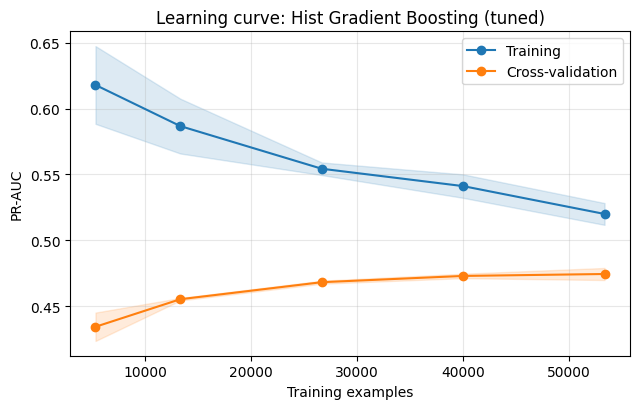

In [ ]:
X_lc, y_lc = stratified_sample(X_train, y_train, LC_N)
sizes, tr, va = learning_curve(build(best_name).set_params(**best_params[best_name]), X_lc, y_lc,
                               train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0], cv=cv,
                               scoring="average_precision", n_jobs=1, random_state=SEED)
plt.figure(figsize=(6.5, 4.2))
for arr, lab, col in [(tr, "Training", "tab:blue"), (va, "Cross-validation", "tab:orange")]:
    plt.plot(sizes, arr.mean(1), "o-", label=lab, color=col)
    plt.fill_between(sizes, arr.mean(1) - arr.std(1), arr.mean(1) + arr.std(1), alpha=0.15, color=col)
plt.xlabel("Training examples"); plt.ylabel("PR-AUC"); plt.title(f"Learning curve: {LABELS[best_name]}")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); show_fig("learning_curve")

**Interpretation:** The curves have not fully converged: training PR-AUC falls from about 0.62 to 0.52 as data grows, while cross-validated PR-AUC rises from about 0.435 to 0.475. The gap at the largest size is about 0.045, which is mild overfitting. The cross-validation curve is nearly flat over the last two points (about 0.473 to 0.475), so more data of the same kind would help only marginally. The curve only reaches about 53,000 rows because it uses an 80,000-row subsample with 3-fold CV so extrapolating to the full 188,000 rows should be done cautiously. Better or additional predictors, such as spirometry-related symptoms or occupational exposure are more likely to help than more respondents.

### 2.12 Final evaluation on the held-out test set

Every model is applied to the test set with the threshold chosen on validation. Curves compare ranking quality (ROC and precision-recall), and the confusion matrix shows the selected model's errors at its threshold.

,ROC-AUC,PR-AUC,threshold,recall,precision,F1,F2,balanced acc,flagged %
model,,,,,,,,,
Logistic Regression (tuned),0.853,0.464,0.523,0.756,0.304,0.434,0.583,0.776,26.255
Random Forest (tuned),0.854,0.465,0.407,0.781,0.288,0.421,0.582,0.776,28.652
Hist Gradient Boosting (tuned),0.859,0.480,0.532,0.767,0.312,0.443,0.594,0.783,25.983
"SVM (RBF, subsample)",0.823,0.374,-0.429,0.765,0.254,0.381,0.545,0.750,31.878


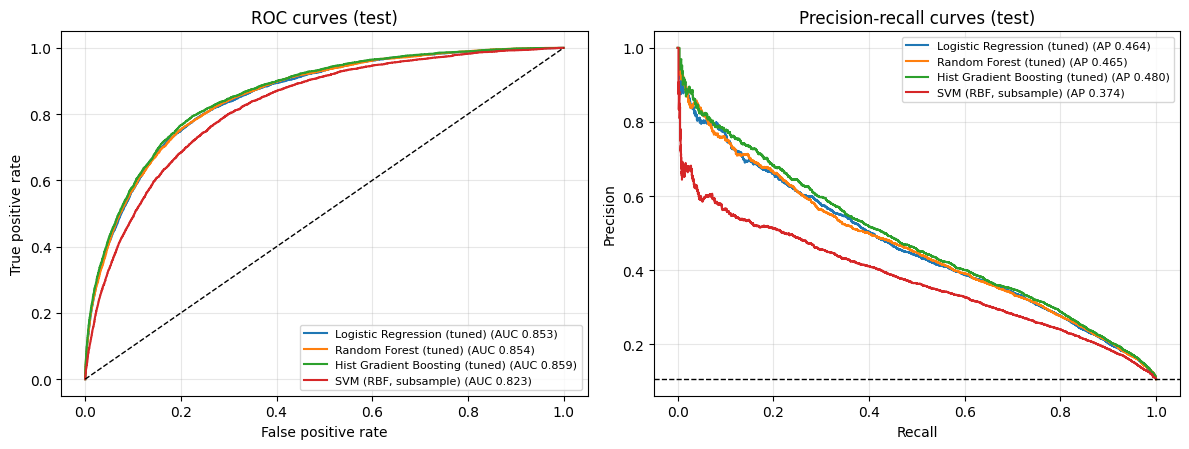

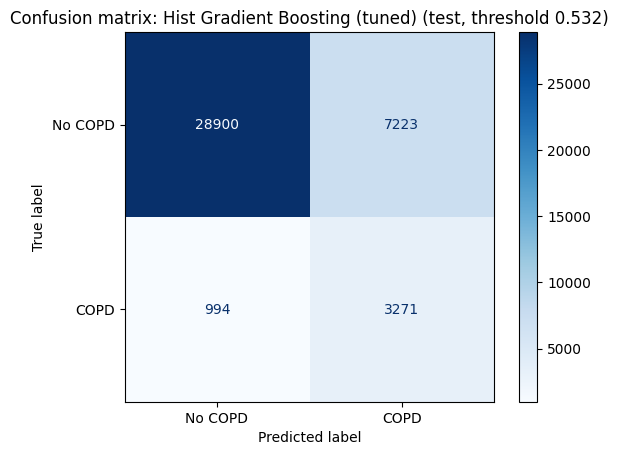

In [ ]:
test_scores, test_rows = {}, []
for name, m in tuned.items():
    s = get_scores(m, X_test); test_scores[LABELS[name]] = s
    test_rows.append({"model": LABELS[name], **metrics(y_test, s, tuned_val[name]["thr"])})
svm = fitted["SVM (RBF, subsample)"]
s = get_scores(svm, X_test); test_scores["SVM (RBF, subsample)"] = s
test_rows.append({"model": "SVM (RBF, subsample)", **metrics(y_test, s, best_threshold(y_val, val_scores["SVM (RBF, subsample)"]))})
test_table = pd.DataFrame(test_rows).set_index("model")
display(test_table.round(3))
wb_table("test_results", test_table.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for lab, s in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, s); ax[0].plot(fpr, tpr, label=f"{lab} (AUC {roc_auc_score(y_test, s):.3f})")
    p, r, _ = precision_recall_curve(y_test, s); ax[1].plot(r, p, label=f"{lab} (AP {average_precision_score(y_test, s):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (test)")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1); ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curves (test)")
for a in ax: a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); show_fig("roc_pr_curves")

best_test_scores = test_scores[LABELS[best_name]]
pred = (best_test_scores >= best_thr).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["No COPD", "COPD"]).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion matrix: {LABELS[best_name]} (test, threshold {best_thr:.3f})"); show_fig("confusion_matrix")
wb_summary({"best_model": LABELS[best_name], "threshold": float(best_thr),
            **{f"test/{k}": float(v) for k, v in test_table.loc[LABELS[best_name]].items()}})

**Interpretation:** Tuned boosting also wins on the test set. The ranking matches validation: boosting, then logistic regression (0.464) and random forest (0.465), with the SVM last (0.374). Test PR-AUC is about 0.01 lower than on validation which is expected after selecting on validation. The confusion matrix shows 3,271 true positives, 994 missed cases, 7,223 false alarms and 28,900 true negatives. About 23% of real cases are missed, and about 26% of people are flagged, so there are roughly 2.2 false alarms per true case. Precision of 31% is about three times the 10.6% base rate. That is useful for prioritising who gets a breathing test but it is not strong enough to diagnose which matches the intended use as a screening aid. Some “false alarms” may be undiagnosed COPD, since those people are labelled negative.

### 2.13 Threshold analysis

A screening tool is only useful if its trade-off can be stated in plain terms. For several target recall levels, the threshold is fixed on the validation set and then applied to the test set, showing what share of people would be flagged and how many of the flagged are real cases (precision).

,target recall (val),threshold,test recall,test precision,people flagged %
0,0.6,0.697,0.594,0.403,15.567
1,0.7,0.606,0.702,0.348,21.303
2,0.8,0.473,0.807,0.282,30.177
3,0.9,0.312,0.892,0.216,43.602


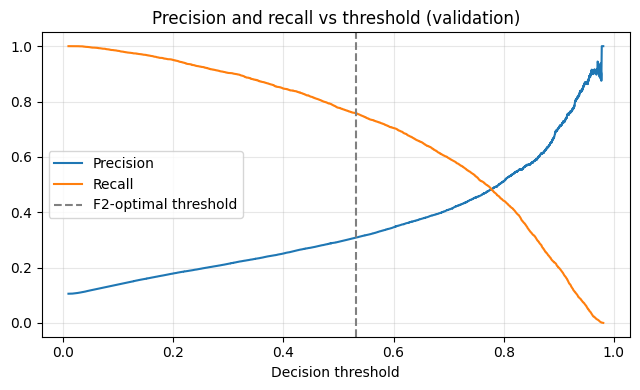

In [ ]:
s_val = tuned_val[best_name]["scores"]
rows = []
for target in [0.60, 0.70, 0.80, 0.90]:
    prec, rec, thr = precision_recall_curve(y_val, s_val)
    ok = np.where(rec[:-1] >= target)[0]
    t = thr[ok[-1]]
    m = metrics(y_test, best_test_scores, t)
    rows.append({"target recall (val)": target, "threshold": t, "test recall": m["recall"],
                 "test precision": m["precision"], "people flagged %": m["flagged %"]})
thr_tbl = pd.DataFrame(rows).round(3)
display(thr_tbl)
wb_table("threshold_analysis", thr_tbl)

p, r, t = precision_recall_curve(y_val, s_val)
plt.figure(figsize=(6.5, 4)); plt.plot(t, p[:-1], label="Precision"); plt.plot(t, r[:-1], label="Recall")
plt.axvline(best_thr, color="gray", ls="--", label="F2-optimal threshold")
plt.xlabel("Decision threshold"); plt.title("Precision and recall vs threshold (validation)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); show_fig("precision_recall_vs_threshold")

### 2.14 Which features matter? Permutation importance and ablation

**Permutation importance** shuffles one feature at a time on validation data and measures how much PR-AUC drops. **Group ablation** retrains the model without a whole group of features. Together they test the feature list from Part 1 with evidence instead of assumption. Strongly correlated features can share importance, so read the ablation results alongside the importance plot.

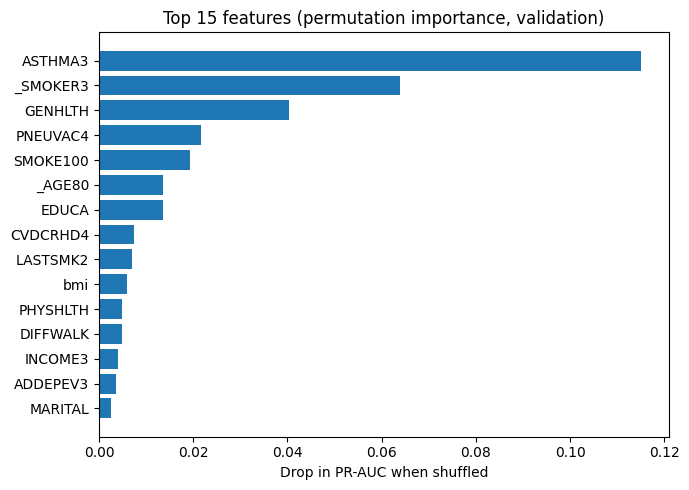

In [ ]:
X_pi, y_pi = stratified_sample(X_val, y_val, PI_N)
pi = permutation_importance(best_model, X_pi, y_pi, scoring="average_precision", n_repeats=3,
                            random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=ALL_FEATURES).sort_values(ascending=False)
top = imp.head(15)[::-1]
plt.figure(figsize=(7, 5)); plt.barh(top.index, top.values, color="tab:blue")
plt.xlabel("Drop in PR-AUC when shuffled"); plt.title("Top 15 features (permutation importance, validation)")
plt.tight_layout(); show_fig("permutation_importance")
wb_table("permutation_importance", imp.head(20).rename("PR-AUC drop").to_frame())

In [ ]:
GROUPS = {
    "Smoking & tobacco":  ["SMOKE100", "_SMOKER3", "SMOKDAY2", "LASTSMK2", "USENOW3"],
    "Alcohol":            ["alc_days_month", "alc_drinks_week"],
    "Health status":      ["GENHLTH", "PHYSHLTH", "MENTHLTH", "bmi", "EXERANY2", "DIFFWALK", "DIFFDRES", "DIFFALON"],
    "Comorbidities":      ["ASTHMA3", "CVDINFR4", "CVDCRHD4", "CVDSTRK3", "DIABETE4", "BPHIGH6", "TOLDHI3",
                           "ADDEPEV3", "HAVARTH4", "CHCKDNY2"],
    "Socio-demographics": ["MARITAL", "EMPLOY1", "EDUCA", "INCOME3", "VETERAN3", "_URBSTAT", "_STATE"],
    "Healthcare use":     ["CHECKUP1", "MEDCOST1", "FLUSHOT7", "PNEUVAC4"],
    "Physical/mental days (leakage check)": ["PHYSHLTH", "MENTHLTH"],
}
full_s = tuned_val[best_name]["scores"]
rows = [{"removed group": "none (all features)", "ROC-AUC": roc_auc_score(y_val, full_s),
         "PR-AUC": average_precision_score(y_val, full_s)}]
for g, cols in GROUPS.items():
    keep = [c for c in ALL_FEATURES if c not in cols]
    m = build(best_name, cols=keep).set_params(**best_params[best_name]).fit(X_train[keep], y_train)
    s = get_scores(m, X_val[keep])
    rows.append({"removed group": g, "ROC-AUC": roc_auc_score(y_val, s), "PR-AUC": average_precision_score(y_val, s)})
abl = pd.DataFrame(rows).set_index("removed group")
abl["PR-AUC change"] = abl["PR-AUC"] - abl.loc["none (all features)", "PR-AUC"]
wb_table("feature_group_ablation", abl.round(4))
abl.round(4)

,ROC-AUC,PR-AUC,PR-AUC change
removed group,,,
none (all features),0.8620,0.4900,0.0000
Smoking & tobacco,0.8336,0.4340,-0.0560
Alcohol,0.8617,0.4880,-0.0020
Health status,0.8488,0.4534,-0.0367
Comorbidities,0.8347,0.4179,-0.0721
Socio-demographics,0.8571,0.4767,-0.0133
Healthcare use,0.8586,0.4790,-0.0111
Physical/mental days (leakage check),0.8615,0.4861,-0.0039


**Interpretation:** The comorbidity group costs the most when removed (PR-AUC −0.072), followed by smoking and tobacco (−0.056) and health status (−0.037). Smoking is therefore important but not the single dominant group. Permutation importance singles out asthma (about 0.115 drop), well ahead of _SMOKER3 (about 0.064) and GENHLTH (about 0.040). Several smoking variables overlap, so shuffling any one of them understates the group’s value and the ablation is the fairer measure. Removing PHYSHLTH and MENTHLTH lowers PR-AUC by only 0.004 (ROC-AUC essentially unchanged), so there is no leakage warning. Alcohol (−0.002) can be dropped with almost no loss. Socio-demographics (−0.013) and healthcare use (−0.011) matter little. The asthma result likely also reflects diagnostic overlap between asthma and COPD and GENHLTH may partly capture respiratory symptoms.

### 2.15 Error analysis by subgroup

Recall and precision at the selected threshold are broken down by sex, age band, smoking status and income band on the **test set**. Large differences in recall between subgroups are a fairness and reliability concern worth discussing in the report. Groups with very few people give unstable estimates.

In [ ]:
meta = df.loc[idx_test, META + ["is_female", "_SMOKER3", "INCOME3"]].copy()
meta["y"], meta["pred"] = y_test, pred

meta["Sex"] = np.where(meta["is_female"] == 1, "Female", "Male")
meta["Age band"] = meta["_AGEG5YR"].map({7: "50-54", 8: "55-59", 9: "60-64", 10: "65-69", 11: "70-74", 12: "75-79", 13: "80+"})
meta["Smoking"] = meta["_SMOKER3"].map({1: "Current (daily)", 2: "Current (some days)", 3: "Former", 4: "Never"}).fillna("Unknown")
meta["Income"] = pd.cut(meta["INCOME3"], [0, 4, 7, 11], labels=["< $25k", "$25k-$75k", "> $75k"]).astype(object).fillna("Unknown")

def subgroup_table(col):
    g = meta.groupby(col)
    out = pd.DataFrame({"n": g.size(), "COPD rate": g["y"].mean(),
                        "recall": g.apply(lambda d: recall_score(d["y"], d["pred"]) if d["y"].sum() else np.nan),
                        "precision": g.apply(lambda d: precision_score(d["y"], d["pred"], zero_division=0)),
                        "flagged %": g["pred"].mean() * 100})
    out.index = [f"{col}: {i}" for i in out.index]
    return out

subgroups = pd.concat([subgroup_table(c) for c in ["Sex", "Age band", "Smoking", "Income"]]).round(3)
wb_table("subgroup_error_analysis", subgroups)
subgroups

,n,COPD rate,recall,precision,flagged %
Sex: Female,22234,0.114,0.781,0.330,26.950
Sex: Male,18154,0.096,0.747,0.288,24.799
Age band: 50-54,4740,0.057,0.728,0.309,13.312
Age band: 55-59,5155,0.082,0.749,0.316,19.379
Age band: 60-64,6243,0.105,0.788,0.339,24.363
Age band: 65-69,6853,0.116,0.786,0.338,26.966
Age band: 70-74,6554,0.117,0.766,0.305,29.356
Age band: 75-79,5142,0.134,0.767,0.309,33.256
Age band: 80+,5701,0.118,0.752,0.271,32.643
Smoking: Current (daily),3048,0.308,0.962,0.391,75.787


In [ ]:
fn = meta[(meta.y == 1) & (meta.pred == 0)]
tp = meta[(meta.y == 1) & (meta.pred == 1)]
share = lambda d: d["Smoking"].value_counts(normalize=True).round(3)
pd.DataFrame({"missed cases (false negatives)": share(fn), "caught cases (true positives)": share(tp)}).fillna(0)

,missed cases (false negatives),caught cases (true positives)
Smoking,,
Current (daily),0.036,0.276
Current (some days),0.032,0.070
Former,0.381,0.474
Never,0.495,0.139
Unknown,0.055,0.040


**Interpretation:** Sex and age show little variation: recall is 0.78 for women and 0.75 for men and 0.73 to 0.79 across age bands. The large gaps are by smoking and income. Recall is 0.96 for daily smokers but only 0.48 for never-smokers, and 0.89 for people under $25k against 0.55 above $75k. Never-smokers make up about half of all missed cases (49.5%) but only 14% of caught cases and former smokers account for another 38% of misses. The model is largely a proxy for smoking history plus asthma and poor health. A screening programme built on it would systematically overlook never-smoking and higher-income people with COPD who also have lower base rates (4.3% and 5.2%). Daily smokers, by contrast are flagged 76% of the time. The 50–54 band has only 268 cases so its figures are unstable.

### 2.16 Save the best model, threshold and split

The pipeline (preprocessing + model), the decision threshold and the split indices are saved to the Drive folder. The split indices point to rows of the Part 1 Parquet file, so the deep learning part (Part 3) can load exactly the same train/validation/test rows.

In [ ]:
joblib.dump(best_model, f"{MODEL_DIR}/best_traditional_model{SUFFIX}.joblib")
np.savez(f"{MODEL_DIR}/split_indices{SUFFIX}.npz", train=idx_train, val=idx_val, test=idx_test)
with open(f"{MODEL_DIR}/best_traditional_meta{SUFFIX}.json", "w") as f:
    json.dump({"model": LABELS[best_name], "threshold": float(best_thr), "params": {k: str(v) for k, v in best_params[best_name].items()},
               "test_metrics": {k: float(v) for k, v in test_table.loc[LABELS[best_name]].items()},
               "features": ALL_FEATURES, "seed": SEED}, f, indent=2)
test_table.round(4).to_csv(f"{MODEL_DIR}/traditional_test_results{SUFFIX}.csv")
print(os.listdir(MODEL_DIR))

if RUN is not None:
    art = wandb.Artifact("best-traditional-model", type="model",
                         metadata={"model": LABELS[best_name], "threshold": float(best_thr)})
    model_file = f"{MODEL_DIR}/best_traditional_model{SUFFIX}.joblib"
    if os.path.getsize(model_file) < 500e6:          # skip very large models (e.g. a huge Random Forest)
        art.add_file(model_file)
    art.add_file(f"{MODEL_DIR}/best_traditional_meta{SUFFIX}.json")
    art.add_file(f"{MODEL_DIR}/split_indices{SUFFIX}.npz")
    RUN.log_artifact(art)
wb_end()

['best_traditional_model_quick.joblib', 'traditional_test_results_quick.csv', 'best_traditional_meta_quick.json', 'split_indices_quick.npz', 'best_dl_model_quick.keras', 'best_dl_model_quick.h5', 'best_dl_savedmodel_quick', 'dl_preprocessing_quick.joblib', 'best_dl_meta_quick.json', 'dl_experiment_results_quick.csv', 'best_traditional_model.joblib', 'split_indices.npz', 'best_traditional_meta.json', 'traditional_test_results.csv', 'best_dl_model.keras', 'best_dl_model.h5', 'best_dl_savedmodel', 'dl_preprocessing.joblib', 'best_dl_meta.json', 'dl_experiment_results.csv']


wandb: WARNING Artifact "best-traditional-model" already exists with the same content. No new version will be created.


best_model,Hist Gradient Boosti...
test/F1,0.44325
test/F2,0.59356
test/PR-AUC,0.4797
test/ROC-AUC,0.85926
test/balanced acc,0.78349
test/flagged %,25.98297
test/precision,0.3117
test/recall,0.76694
test/threshold,0.53205
+1,...


### 2.17 Summary

The best traditional model is a tuned histogram gradient boosting classifier (learning rate = 0.088, 21 leaf nodes, minimum leaf size 40, L2 = 8.6, balanced class weights, threshold 0.532). On the held-out test set it reaches ROC-AUC 0.859, PR-AUC 0.480, recall 0.767 and precision 0.312, flagging 26% of people. Comorbidities (especially asthma), smoking history and self-rated health are the most important groups. The main weakness is recall for never-smokers (0.48) and high-income respondents (0.55).

**Limitations:** self-reported diagnoses, undiagnosed cases labelled negative, cross-sectional data, and discrimination that plateaus quickly with the available features. These numbers are the benchmark for Part 3.

## Part 3. Deep learning (TensorFlow/Keras)

This part trains neural networks on **exactly the same train / validation / test rows** as Part 2, so the comparison with the traditional models is fair. It uses the Keras **Functional API** and a **`tf.data`** input pipeline.

### 3.1 Setup and checks

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import OrdinalEncoder

keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

DL_EPOCHS   = 100 if not QUICK_RUN else 3
DL_PATIENCE = 8
DL_BATCH    = 1024
BOOTSTRAPS  = 200 if not QUICK_RUN else 40

needed = ["df", "y", "idx_train", "idx_val", "idx_test", "X_train", "X_val", "X_test", "y_train", "y_val", "y_test",
          "ALL_FEATURES", "CONT", "BINARY", "ORDINAL", "NOMINAL", "make_preprocessor", "metrics", "best_threshold",
          "get_scores", "Winsorizer", "wb_start", "wb_end", "wb_log", "wb_table"]
absent = [n for n in needed if n not in globals()]
assert not absent, f"Run Part 0 and sections 2.1-2.5 first. Missing: {absent}"

# the split must be identical to the one saved by Part 2
split_file = f"{MODEL_DIR}/split_indices{SUFFIX}.npz"
if os.path.exists(split_file):
    saved = np.load(split_file)
    assert all((saved[k] == v).all() for k, v in zip(["train", "val", "test"], [idx_train, idx_val, idx_test])), "split differs from Part 2"
    print("Split matches the one saved by Part 2.")

TensorFlow 2.21.0 | GPUs: []
Split matches the one saved by Part 2.


### 3.2 Data preparation

The preprocessing is the one used in Part 2 (clip outliers, impute with missing-indicators, scale numeric features, one-hot encode categoricals) and is **fitted on the training rows only**. The result is a dense `float32` matrix per split. Class weights are computed from the training labels so that the rare COPD class counts as much as the common one during training.

In [ ]:
prep = make_preprocessor(ALL_FEATURES, "indicator", scale=True)
Xtr = prep.fit_transform(X_train).astype("float32")
Xva = prep.transform(X_val).astype("float32")
Xte = prep.transform(X_test).astype("float32")
print("feature matrices:", Xtr.shape, Xva.shape, Xte.shape)

n0, n1 = int((y_train == 0).sum()), int((y_train == 1).sum())
CLASS_WEIGHT = {0: 0.5 * len(y_train) / n0, 1: 0.5 * len(y_train) / n1}
print("class weights:", {k: round(v, 3) for k, v in CLASS_WEIGHT.items()})

feature matrices: (188476, 157) (40388, 157) (40388, 157)
class weights: {0: 0.559, 1: 4.735}


### 3.3 `tf.data` input pipelines

Each split becomes a `tf.data.Dataset`. The training pipeline reshuffles every epoch, all pipelines are batched, and `prefetch` prepares the next batch while the current one is being processed. The validation and test pipelines are **not** shuffled, so predictions stay aligned with the labels.

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def make_ds(features, labels, batch, training):
    ds = tf.data.Dataset.from_tensor_slices((features, np.asarray(labels, dtype="float32")))
    if training:
        ds = ds.shuffle(buffer_size=min(len(labels), 100_000), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch).prefetch(AUTOTUNE)

ds_example = make_ds(Xtr, y_train, DL_BATCH, True)
for xb, yb in ds_example.take(1):
    print("one training batch:", xb.shape, yb.shape)

one training batch: (1024, 157) (1024,)


### 3.4 Model definitions (Functional API)

**MLP.** Stacked dense layers; each block is Dense → (batch normalisation) → activation → dropout, followed by a single sigmoid unit that outputs the probability of a COPD report. Width, depth, dropout, L2 strength, batch normalisation, activation and learning rate are all arguments, so the experiments below only change the configuration.

**Embedding model.** A multi-input network: numeric features go in as one vector, while each categorical variable (marital status, employment, diabetes status, smoker status, state, and so on) has its own input and a learned embedding. Embeddings can represent similarities between categories, which one-hot encoding cannot. Missing values are kept as their own category, as in Part 2.

Every model is compiled with binary cross-entropy and tracks ROC-AUC, PR-AUC, precision and recall per epoch.

In [ ]:
def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="roc_auc"), keras.metrics.AUC(name="pr_auc", curve="PR"),
                           keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")])

def dense_stack(x, units, dropout, l2, batchnorm, activation):
    reg = keras.regularizers.l2(l2) if l2 else None
    for i, u in enumerate(units):
        x = layers.Dense(u, activation=None if batchnorm else activation, kernel_regularizer=reg, name=f"dense_{i}")(x)
        if batchnorm:
            x = layers.BatchNormalization(name=f"bn_{i}")(x)
            x = layers.Activation(activation, name=f"act_{i}")(x)
        if dropout:
            x = layers.Dropout(dropout, name=f"drop_{i}")(x)
    return x

def build_mlp(input_dim, units=(128, 64), dropout=0.3, l2=1e-4, batchnorm=True, activation="relu", lr=1e-3):
    inp = keras.Input(shape=(input_dim,), name="features")
    x = dense_stack(inp, units, dropout, l2, batchnorm, activation)
    out = layers.Dense(1, activation="sigmoid", name="copd_probability")(x)
    model = keras.Model(inp, out, name="mlp")
    compile_model(model, lr)
    return model

# ---- embedding model: data preparation -------------------------------------
NUM_COLS = CONT + BINARY + ORDINAL
CAT_KEYS = ["cat_" + c.strip("_") for c in NOMINAL]

num_prep = make_preprocessor(NUM_COLS, "indicator", scale=True)
Xn_tr = num_prep.fit_transform(X_train[NUM_COLS]).astype("float32")
Xn_va = num_prep.transform(X_val[NUM_COLS]).astype("float32")
Xn_te = num_prep.transform(X_test[NUM_COLS]).astype("float32")

cat_enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
fill = lambda d: d[NOMINAL].fillna(-1)               # missing / "not asked" becomes its own category
C_tr = cat_enc.fit_transform(fill(X_train)).astype("int32") + 1   # +1 so that unseen categories map to 0
C_va = cat_enc.transform(fill(X_val)).astype("int32") + 1
C_te = cat_enc.transform(fill(X_test)).astype("int32") + 1
CARDS = [len(c) + 1 for c in cat_enc.categories_]

def emb_features(Xn, C):
    return {"numeric": Xn, **{k: C[:, i:i + 1] for i, k in enumerate(CAT_KEYS)}}

def build_embedding_model(num_dim, cards, units=(128, 64), dropout=0.3, l2=1e-4, lr=1e-3, batchnorm=True, activation="relu"):
    num_in = keras.Input(shape=(num_dim,), name="numeric")
    cat_ins, embs = [], []
    for key, card in zip(CAT_KEYS, cards):
        i = keras.Input(shape=(1,), dtype="int32", name=key)
        e = layers.Embedding(card, min(8, card // 2 + 1), name="emb_" + key[4:])(i)
        cat_ins.append(i); embs.append(layers.Flatten()(e))
    x = layers.Concatenate()([num_in] + embs)
    x = dense_stack(x, units, dropout, l2, batchnorm, activation)
    out = layers.Dense(1, activation="sigmoid", name="copd_probability")(x)
    model = keras.Model([num_in] + cat_ins, out, name="embedding_mlp")
    compile_model(model, lr)
    return model

build_mlp(Xtr.shape[1]).summary()

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 157)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_0 (Dense)                 │ (None, 128)            │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_0 (BatchNormalization)       │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act_0 (Activation)              │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_0 (Dropout)                │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act_1 (Activation)              │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ copd_probability (Dense)        │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,313 (114.50 KB)

 Trainable params: 28,929 (113.00 KB)

 Non-trainable params: 384 (1.50 KB)

### 3.5 Training helper

One function trains a configuration and records everything in the same way: it builds the model, trains it on the `tf.data` pipeline with class weights, early stopping and learning-rate reduction, logs every epoch to Weights & Biases, scores the validation set, picks the F2-optimal threshold on the validation set and stores the metrics. All experiments call it, so they are compared on identical terms. Random seeds are fixed before each run.

In [ ]:
class WBLogger(keras.callbacks.Callback):
    # sends the metrics of every epoch to the active Weights & Biases run
    def on_epoch_end(self, epoch, logs=None):
        row = {"epoch": epoch + 1, **{k: float(v) for k, v in (logs or {}).items()}}
        try:
            row["lr"] = float(keras.ops.convert_to_numpy(self.model.optimizer.learning_rate))
        except Exception:
            pass
        wb_log(row)

DL_RESULTS, DL_STORE = [], {}

def train_dnn(name, group, cfg=None, embed=False):
    cfg = {"units": (128, 64), "dropout": 0.3, "l2": 1e-4, "batchnorm": True, "activation": "relu",
           "lr": 1e-3, "batch": DL_BATCH, **(cfg or {})}
    wb_start(name, group, {**{k: str(v) for k, v in cfg.items()}, "embeddings": embed, "max_epochs": DL_EPOCHS})
    keras.utils.set_random_seed(SEED)
    arch = {k: cfg[k] for k in ("units", "dropout", "l2", "batchnorm", "activation", "lr")}
    if embed:
        model = build_embedding_model(Xn_tr.shape[1], CARDS, **arch)
        f_tr, f_va = emb_features(Xn_tr, C_tr), emb_features(Xn_va, C_va)
    else:
        model = build_mlp(Xtr.shape[1], **arch)
        f_tr, f_va = Xtr, Xva
    ds_tr, ds_va = make_ds(f_tr, y_train, cfg["batch"], True), make_ds(f_va, y_val, 4096, False)
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=DL_PATIENCE, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_pr_auc", mode="max", factor=0.5, patience=3, min_lr=1e-6),
                 WBLogger()]
    t0 = time.time()
    hist = model.fit(ds_tr, validation_data=ds_va, epochs=DL_EPOCHS, class_weight=CLASS_WEIGHT, callbacks=callbacks, verbose=0)
    s = model.predict(ds_va, verbose=0).ravel()
    thr = best_threshold(y_val, s)
    res = {"experiment": name, "group": group, **metrics(y_val, s, thr),
           "epochs run": len(hist.history["loss"]), "best epoch": int(np.argmax(hist.history["val_pr_auc"])) + 1,
           "parameters": model.count_params(), "fit time (s)": time.time() - t0}
    wb_log({f"val/{k}": v for k, v in res.items() if k not in ("experiment", "group")}); wb_end()
    DL_RESULTS.append(res)
    DL_STORE[name] = {"model": model, "history": hist.history, "val_scores": s, "thr": thr, "embed": embed, "cfg": cfg}
    print(f"{name:34s} PR-AUC {res['PR-AUC']:.3f}  ROC-AUC {res['ROC-AUC']:.3f}  epochs {res['epochs run']:3d} (best {res['best epoch']})  {res['fit time (s)']:.0f}s")
    return res

def group_table(group):
    d = pd.DataFrame([r for r in DL_RESULTS if r["group"] == group]).set_index("experiment")
    return d[["PR-AUC", "ROC-AUC", "recall", "precision", "F2", "epochs run", "best epoch", "parameters", "fit time (s)"]].round(3)

### 3.6 Experiment A: architecture (depth and width)

Four MLPs of increasing capacity are trained with the same regularisation and optimiser settings, to find out how much model capacity this problem needs. Tabular health survey data often saturates early, so a larger network is not guaranteed to be better.

In [ ]:
ARCH = {"shallow (64)": (64,), "medium (128-64)": (128, 64), "deep (256-128-64)": (256, 128, 64), "wide (512-256)": (512, 256)}
for label, units in ARCH.items():
    train_dnn(f"arch | {label}", "dl-exp-architecture", {"units": units})
group_table("dl-exp-architecture")

epoch,▁▁▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇███
learning_rate,███████████████▄▄▄▄▄▄▄▄▄▄▄▂▂▂▂▁▁▁▁▁
loss,█▄▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
lr,██████████████▄▄▄▄▄▄▄▄▄▄▄▂▂▂▂▁▁▁▁▁▁
pr_auc,▁▅▆▆▇▇▇▇▇▇▇▇▇▇▇████████████████████
precision,▁▅▆▆▆▆▇▇▇▇▇▇▇▇▇█▇█▇▇█████▇█████████
recall,▁▄▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇█▇▇▇██▇▇▇█▇███████
roc_auc,▁▅▆▆▇▇▇▇▇▇▇▇▇▇▇████████████████████
val/F1,▁
val/F2,▁
+16,...


arch | shallow (64)                PR-AUC 0.489  ROC-AUC 0.862  epochs  35 (best 27)  128s


epoch,▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇██
learning_rate,█████████████▄▄▄▄▄▂▂▂▂▂▁▁▁▁▁
loss,█▅▄▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁
lr,████████████▄▄▄▄▄▂▂▂▂▂▁▁▁▁▁▁
pr_auc,▁▅▆▆▇▇▇▇▇▇▇▇▇▇███▇██████████
precision,▁▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇█████████
recall,▁▅▆▆▆▇▇▇▇▇▇▇▇▇▇▇████▇██████▇
roc_auc,▁▅▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇██████████
val/F1,▁
val/F2,▁
+16,...


arch | medium (128-64)             PR-AUC 0.489  ROC-AUC 0.861  epochs  28 (best 20)  141s


epoch,▁▁▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇██
learning_rate,██████████████▄▄▄▄▂▂▂▁▁
loss,█▅▄▄▄▃▃▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁
lr,█████████████▄▄▄▄▂▂▂▁▁▁
pr_auc,▁▅▆▆▇▇▇▇▇▇▇▇▇▇█████████
precision,▁▅▆▆▇▇▇▇▇▇▇▇▇▇▇▇█▇█████
recall,▁▃▄▄▅▅▅▆▅▆▆▆▆▆▇▇▇▇█▇███
roc_auc,▁▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇█████
val/F1,▁
val/F2,▁
+16,...


arch | deep (256-128-64)           PR-AUC 0.490  ROC-AUC 0.861  epochs  23 (best 15)  188s


epoch,▁▁▂▂▃▃▃▄▄▅▅▅▆▆▆▇▇██
learning_rate,██████████▄▄▄▄▂▂▂▁▁
loss,█▅▅▄▄▃▃▃▃▃▂▂▂▂▂▁▁▁▁
lr,█████████▄▄▄▄▂▂▂▁▁▁
pr_auc,▁▅▆▆▆▆▆▆▇▇▇▇▇▇▇████
precision,▁▄▄▅▅▅▆▅▅▅▆▆▇▇▇█▇██
recall,▁▄▅▅▅▆▆▆▆▆▆▇▇▇▇▇███
roc_auc,▁▄▅▅▅▆▆▆▆▆▆▇▇▇▇▇███
val/F1,▁
val/F2,▁
+16,...


arch | wide (512-256)              PR-AUC 0.488  ROC-AUC 0.861  epochs  19 (best 11)  295s


,PR-AUC,ROC-AUC,recall,precision,F2,epochs run,best epoch,parameters,fit time (s)
experiment,,,,,,,,,
arch | shallow (64),0.489,0.862,0.764,0.309,0.590,35,27,10433,128.146
arch | medium (128-64),0.489,0.861,0.776,0.300,0.590,28,20,29313,141.442
arch | deep (256-128-64),0.490,0.861,0.762,0.308,0.588,23,15,83457,187.576
arch | wide (512-256),0.488,0.861,0.766,0.305,0.588,19,11,215553,295.074


**Interpretation:** A bigger network does not help. Validation PR-AUC is 0.489 for the shallow model, 0.489 for medium, 0.490 for deep and 0.488 for wide, a spread of 0.002 that is well within run-to-run noise. Parameters rise from about 10,000 to about 216,000 and training time from 128 s to 295 s with no benefit so the extra layers never pay off. The shallow 64-unit network is as good as any and is the sensible choice on parsimony alone.

### 3.7 Experiment B: regularisation

The medium network (128-64) from Experiment A is the reference. Variants remove regularisation entirely, use stronger dropout, use stronger L2 weight decay, or remove batch normalisation. Regularisation fights overfitting, which should show up as a smaller gap between training and validation curves.

In [ ]:
REG = {"no regularisation": dict(dropout=0.0, l2=0.0), "dropout 0.5": dict(dropout=0.5),
       "L2 1e-3": dict(l2=1e-3), "no batch norm": dict(batchnorm=False)}
for label, cfg in REG.items():
    train_dnn(f"reg | {label}", "dl-exp-regularisation", {"units": (128, 64), **cfg})
pd.concat([group_table("dl-exp-architecture").loc[["arch | medium (128-64)"]].rename(index={"arch | medium (128-64)": "reference (dropout 0.3, L2 1e-4, BN)"}),
           group_table("dl-exp-regularisation")])

epoch,▁▂▂▃▃▄▅▅▆▆▇▇█
learning_rate,████████▃▃▃▁▁
loss,█▆▅▅▄▄▄▃▃▂▂▁▁
lr,███████▃▃▃▁▁▁
pr_auc,▁▄▄▅▅▅▆▆▇▇▇██
precision,▁▃▄▄▅▅▅▆▆▇▇██
recall,▁▂▃▃▄▄▅▅▆▇▇██
roc_auc,▁▃▄▄▅▅▅▆▇▇▇██
val/F1,▁
val/F2,▁
+16,...


reg | no regularisation            PR-AUC 0.476  ROC-AUC 0.857  epochs  13 (best 5)  64s


epoch,▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███
learning_rate,███████████████████████▄▄▄▄▄▄▄▂▂▂▂▂▁▁▁▁▁
loss,█▄▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
lr,██████████████████████▄▄▄▄▄▄▄▂▂▂▂▂▁▁▁▁▁▁
pr_auc,▁▅▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇███████████████████
precision,▁▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇█████████████
recall,▁▆▇▇▇▇▇▇▇▇█▇█▇▇▇██▇██▇█████▇████████████
roc_auc,▁▅▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇▇██████████████████
val/F1,▁
val/F2,▁
+16,...


reg | dropout 0.5                  PR-AUC 0.490  ROC-AUC 0.861  epochs  40 (best 32)  175s


epoch,▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇██
learning_rate,█████████████▄▄▄▄▄▂▂▂▂▂▁▁▁▁▁
loss,█▅▄▃▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁
lr,████████████▄▄▄▄▄▂▂▂▂▂▁▁▁▁▁▁
pr_auc,▁▅▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇█▇███████
precision,▁▄▅▅▅▆▅▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇█████
recall,▁▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇▇█▇▇▇▇██████
roc_auc,▁▅▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇██████
val/F1,▁
val/F2,▁
+16,...


reg | L2 1e-3                      PR-AUC 0.490  ROC-AUC 0.861  epochs  28 (best 20)  133s


epoch,▁▁▂▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇██
learning_rate,███████████████▄▄▄▄▂▂▂▂▁▁▁▁▁
loss,█▅▄▄▄▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
lr,██████████████▄▄▄▄▂▂▂▂▁▁▁▁▁▁
pr_auc,▁▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇█████████
precision,▁▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇█████████
recall,▁▄▅▅▅▆▅▆▆▆▆▆▆▇▆▇▇▇▇▇▇█▇█████
roc_auc,▁▄▅▅▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇████████
val/F1,▁
val/F2,▁
+16,...


reg | no batch norm                PR-AUC 0.489  ROC-AUC 0.859  epochs  28 (best 20)  112s


,PR-AUC,ROC-AUC,recall,precision,F2,epochs run,best epoch,parameters,fit time (s)
experiment,,,,,,,,,
"reference (dropout 0.3, L2 1e-4, BN)",0.489,0.861,0.776,0.300,0.590,28,20,29313,141.442
reg | no regularisation,0.476,0.857,0.768,0.300,0.585,13,5,29313,63.670
reg | dropout 0.5,0.490,0.861,0.756,0.313,0.589,40,32,29313,174.636
reg | L2 1e-3,0.490,0.861,0.780,0.296,0.588,28,20,29313,132.640
reg | no batch norm,0.489,0.859,0.762,0.308,0.588,28,20,28545,111.643


**Interpretation:** Regularisation matters. With none, PR-AUC drops to 0.476 (from 0.489) and ROC-AUC to 0.857, and the best epoch is just 5, so the network overfits almost immediately. Dropout 0.5 and L2 1e-3 both reach 0.490 matching the reference. Removing batch normalisation barely changes accuracy (0.489, ROC-AUC 0.859) and trains a bit faster (112 s against 141 s) with the same epoch count so there was no sign of instability. Moderate regularisation of any kind is enough and batch normalisation is not essential for a network this small.

### 3.8 Experiment C: optimisation (learning rate and batch size)

Learning rate and batch size control how fast and how stably the network learns. A rate that is too high makes training unstable, while one that is too low is slow and may stop early on a plateau. The default is a learning rate of 1e-3 and a batch size of 1,024.

In [ ]:
OPT = {"lr 1e-2": dict(lr=1e-2), "lr 1e-4": dict(lr=1e-4), "batch 512": dict(batch=512), "batch 4096": dict(batch=4096)}
for label, cfg in OPT.items():
    train_dnn(f"opt | {label}", "dl-exp-optimisation", {"units": (128, 64), **cfg})
pd.concat([group_table("dl-exp-architecture").loc[["arch | medium (128-64)"]].rename(index={"arch | medium (128-64)": "reference (lr 1e-3, batch 1024)"}),
           group_table("dl-exp-optimisation")])

epoch,▁▁▂▂▂▂▃▃▃▃▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇██
learning_rate,████▄▄▄▄▃▃▃▃▃▃▃▃▃▃▂▂▂▂▁▁▁▁▁
loss,█▆▆▆▅▅▅▅▄▄▄▄▃▄▄▃▃▃▃▃▃▂▂▂▂▁▁
lr,███▄▄▄▄▃▃▃▃▃▃▃▃▃▃▂▂▂▂▁▁▁▁▁▁
pr_auc,▁▄▄▄▅▅▅▅▆▆▆▆▆▆▆▆▆▆▇▇▇▇▇████
precision,▁▃▄▄▅▄▄▄▅▅▅▅▆▅▅▆▅▆▆▇▆▇▇▇▇▇█
recall,▁▂▁▂▁▂▁▂▃▂▂▃▃▄▄▃▄▄▅▅▅▅▆▇▇██
roc_auc,▁▃▃▃▄▄▄▄▅▅▅▅▅▅▅▅▅▅▆▆▆▆▇▇▇██
val/F1,▁
val/F2,▁
+16,...


opt | lr 1e-2                      PR-AUC 0.491  ROC-AUC 0.860  epochs  27 (best 19)  116s


epoch,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▆▆▆▇▇▇▇▇▇███
learning_rate,█████████████████████████▃▃▃▂▂▁▁▁▁▁▁▁▁▁▁
loss,█▅▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
lr,████████████████████████▄▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁
pr_auc,▁▅▆▆▆▇▇▇▇▇▇▇▇▇██████████████████████████
precision,▁▄▅▅▆▆▇▇▇▇▇▇████████████████████████████
recall,▁▃▄▅▅▆▇▇▇▇▇▇▇▇▇██▇█▇██▇█████████████████
roc_auc,▁▃▄▅▆▇▇▇▇▇▇▇▇▇▇▇▇███████████████████████
val/F1,▁
val/F2,▁
+16,...


opt | lr 1e-4                      PR-AUC 0.487  ROC-AUC 0.861  epochs  85 (best 77)  376s


epoch,▁▁▂▂▂▂▃▃▃▃▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇██
learning_rate,██████████████████▄▄▄▄▂▂▂▁▁
loss,█▅▄▄▄▃▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▁▁▁▁▁
lr,█████████████████▄▄▄▄▂▂▂▁▁▁
pr_auc,▁▅▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇▇█████
precision,▁▄▄▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇██████
recall,▁▅▅▆▆▆▆▆▆▆▆▆▇▆▆▆▆▇▇▇▇▇▇▇▇██
roc_auc,▁▅▅▅▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇█████
val/F1,▁
val/F2,▁
+16,...


opt | batch 512                    PR-AUC 0.490  ROC-AUC 0.860  epochs  27 (best 19)  146s


epoch,▁▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇███
learning_rate,███████████████████████████▄▄▄▄▄▄▂▂▂▁▁
loss,█▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
lr,██████████████████████████▄▄▄▄▄▄▂▂▂▁▁▁
pr_auc,▁▄▅▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇█▇██████████████████
precision,▁▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇████▇▇████████████
recall,▁▆▆▇▇▇▇▇████▇█████▇█▇█▇████▇██████████
roc_auc,▁▅▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇█████████████████████
val/F1,▁
val/F2,▁
+16,...


opt | batch 4096                   PR-AUC 0.490  ROC-AUC 0.862  epochs  38 (best 30)  141s


,PR-AUC,ROC-AUC,recall,precision,F2,epochs run,best epoch,parameters,fit time (s)
experiment,,,,,,,,,
"reference (lr 1e-3, batch 1024)",0.489,0.861,0.776,0.300,0.590,28,20,29313,141.442
opt | lr 1e-2,0.491,0.860,0.784,0.295,0.589,27,19,29313,116.281
opt | lr 1e-4,0.487,0.861,0.768,0.306,0.590,85,77,29313,376.438
opt | batch 512,0.490,0.860,0.764,0.306,0.588,27,19,29313,145.790
opt | batch 4096,0.490,0.862,0.778,0.301,0.591,38,30,29313,141.186


**Interpretation:** All settings land within 0.004 PR-AUC of each other. Learning rate 1e-2 is nominally best (0.491) and finishes quickly (best epoch 19, 116 s), while 1e-4 is slightly lower (0.487) and needs 85 epochs and 376 s, almost three times as long. Batch sizes 512 and 4096 both give 0.490.

### 3.9 Experiment D: embeddings for categorical variables

The embedding model (multi-input Functional API) replaces one-hot encoding of the ten categorical variables with learned embeddings, while keeping the same hidden layers as the reference MLP. If embeddings help, the categories (for example states or employment types) carry structure that one-hot encoding cannot express.

In [ ]:
train_dnn("embeddings | medium (128-64)", "dl-exp-embeddings", {"units": (128, 64)}, embed=True)
pd.concat([group_table("dl-exp-architecture").loc[["arch | medium (128-64)"]].rename(index={"arch | medium (128-64)": "one-hot MLP (reference)"}),
           group_table("dl-exp-embeddings")])

epoch,▁▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇███
learning_rate,██████████▄▄▄▄▄▄▄▄▄▄▄▄▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁
loss,█▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
lr,█████████▄▄▄▄▄▄▄▄▄▄▄▄▃▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁
pr_auc,▁▅▆▆▇▇▇▇▇▇▇▇████████▇█████████████████
precision,▁▅▅▆▆▆▆▇▇▆▇▇▇▇▇▇▇▇▇▇▇▇█▇██████████████
recall,▁▅▇▇▇▇▇▇██▇▇███▇▇█▇█▇█████████████████
roc_auc,▁▅▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇█████████████████████
val/F1,▁
val/F2,▁
+16,...


embeddings | medium (128-64)       PR-AUC 0.491  ROC-AUC 0.862  epochs  38 (best 30)  298s


,PR-AUC,ROC-AUC,recall,precision,F2,epochs run,best epoch,parameters,fit time (s)
experiment,,,,,,,,,
one-hot MLP (reference),0.489,0.861,0.776,0.300,0.590,28,20,29313,141.442
embeddings | medium (128-64),0.491,0.862,0.769,0.304,0.588,38,30,22715,298.083


**Interpretation:** Embeddings give PR-AUC 0.491 against 0.489 for one-hot, and ROC-AUC 0.862 against 0.861.The embedding model has fewer parameters (22,715 against 29,313) but takes about twice as long to train (298 s against 141 s). The categorical variables apparently carry no structure that one-hot encoding fails to capture.

### 3.10 Model selection and learning curves

All deep learning runs are compared on the validation set. The configuration with the highest validation PR-AUC is selected. Its **learning curves** (loss and PR-AUC per epoch, training against validation) show whether it overfits (validation gets worse while training keeps improving), underfits (both curves stay poor) or trains well (both converge together).

,group,PR-AUC,ROC-AUC,recall,precision,F2,epochs run,best epoch,parameters
experiment,,,,,,,,,
embeddings | medium (128-64),dl-exp-embeddings,0.491,0.862,0.769,0.304,0.588,38,30,22715
opt | lr 1e-2,dl-exp-optimisation,0.491,0.860,0.784,0.295,0.589,27,19,29313
reg | L2 1e-3,dl-exp-regularisation,0.490,0.861,0.780,0.296,0.588,28,20,29313
reg | dropout 0.5,dl-exp-regularisation,0.490,0.861,0.756,0.313,0.589,40,32,29313
opt | batch 4096,dl-exp-optimisation,0.490,0.862,0.778,0.301,0.591,38,30,29313
opt | batch 512,dl-exp-optimisation,0.490,0.860,0.764,0.306,0.588,27,19,29313
arch | deep (256-128-64),dl-exp-architecture,0.490,0.861,0.762,0.308,0.588,23,15,83457
arch | medium (128-64),dl-exp-architecture,0.489,0.861,0.776,0.300,0.590,28,20,29313
reg | no batch norm,dl-exp-regularisation,0.489,0.859,0.762,0.308,0.588,28,20,28545



Selected deep learning model: embeddings | medium (128-64) | validation threshold: 0.539


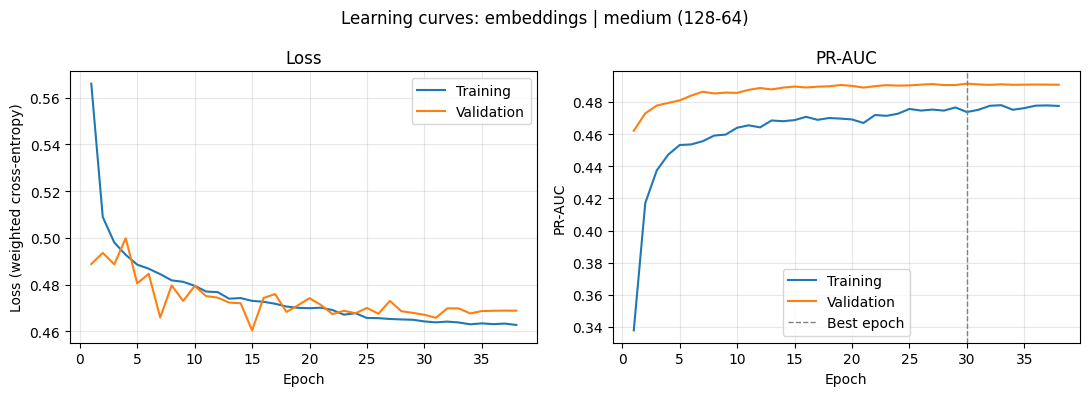

In [ ]:
dl_df = pd.DataFrame(DL_RESULTS).set_index("experiment").sort_values("PR-AUC", ascending=False)
display(dl_df[["group", "PR-AUC", "ROC-AUC", "recall", "precision", "F2", "epochs run", "best epoch", "parameters"]].round(3))

best_dl = dl_df.index[0]
store = DL_STORE[best_dl]
print("\nSelected deep learning model:", best_dl, "| validation threshold:", round(float(store["thr"]), 3))

wb_start("final-dl", "dl-final", {"model": best_dl, **{k: str(v) for k, v in store["cfg"].items()}, "embeddings": store["embed"]}, job_type="evaluate")
wb_table("dl_experiments", dl_df[["group", "PR-AUC", "ROC-AUC", "recall", "precision", "F2", "epochs run", "best epoch", "parameters"]].round(4))

h = store["history"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ep = np.arange(1, len(h["loss"]) + 1)
ax[0].plot(ep, h["loss"], label="Training"); ax[0].plot(ep, h["val_loss"], label="Validation")
ax[0].set(xlabel="Epoch", ylabel="Loss (weighted cross-entropy)", title="Loss")
ax[1].plot(ep, h["pr_auc"], label="Training"); ax[1].plot(ep, h["val_pr_auc"], label="Validation")
ax[1].axvline(int(np.argmax(h["val_pr_auc"])) + 1, color="gray", ls="--", lw=1, label="Best epoch")
ax[1].set(xlabel="Epoch", ylabel="PR-AUC", title="PR-AUC")
for a in ax: a.legend(); a.grid(alpha=0.3)
fig.suptitle(f"Learning curves: {best_dl}"); plt.tight_layout(); show_fig("dl_learning_curves")

**Interpretation:** Validation PR-AUC rises quickly over the first 5–10 epochs, then creeps up to about 0.491 at epoch 30, the best epoch, and stays flat. Early stopping ends training at epoch 38 and restores the epoch-30 weights. There is no overfitting: validation does not deteriorate and training PR-AUC (about 0.477) sits below validation (about 0.491) partly because training metrics are averaged during the epoch with dropout active. The loss curves converge to about 0.463 (training) and 0.469 (validation). Validation loss is noisy early on, with spikes around epochs 4, 15 and 20, and calms later.

### 3.11 Test-set evaluation and comparison with the best traditional model

The selected network is evaluated **once** on the test set, with the threshold chosen on the validation set. It is compared with the best traditional model from Part 2 using the same metrics and the same test rows. The curves show ranking quality, the confusion matrix shows the errors of the network, and **bootstrap confidence intervals** (resampling the test set) show whether the difference between the two models is larger than chance.

,ROC-AUC,PR-AUC,threshold,recall,precision,F1,F2,balanced acc,flagged %
Best traditional: Hist Gradient Boosting (tuned),0.859,0.48,0.532,0.767,0.312,0.443,0.594,0.783,25.983
Best deep learning: embeddings | medium (128-64),0.857,0.48,0.539,0.768,0.302,0.433,0.587,0.779,26.867


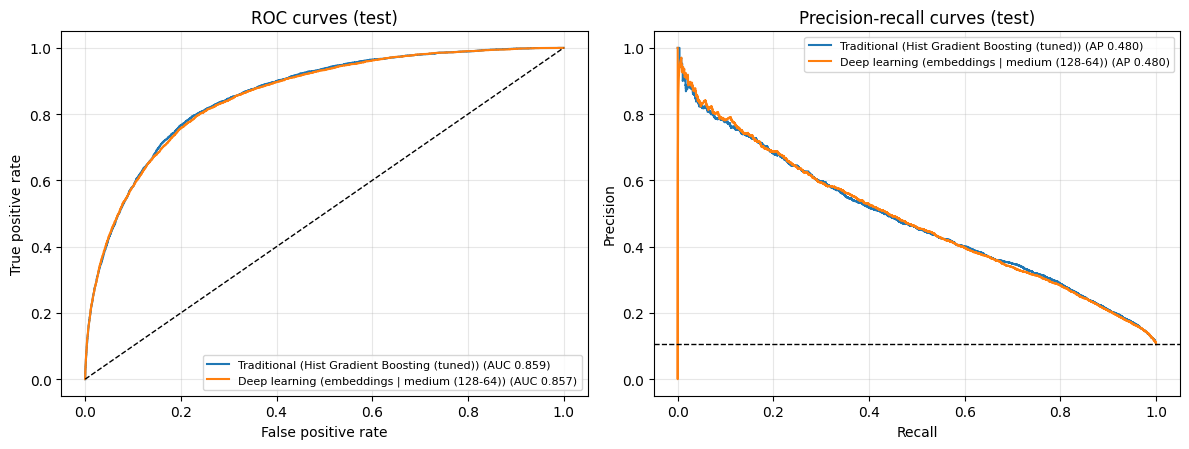

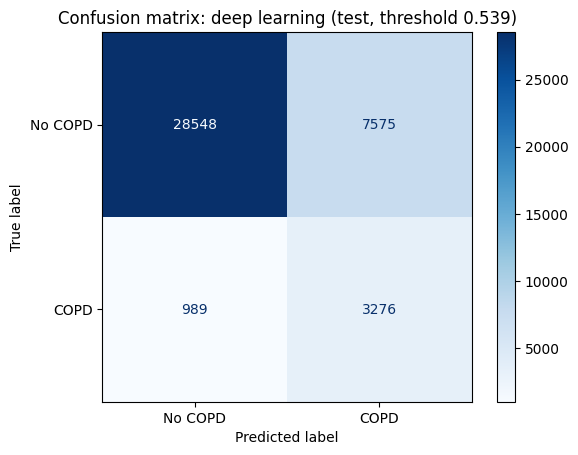

In [ ]:
f_te = emb_features(Xn_te, C_te) if store["embed"] else Xte
dl_scores = store["model"].predict(make_ds(f_te, y_test, 4096, False), verbose=0).ravel()
dl_thr = float(store["thr"])

# best traditional model from Part 2 (from memory, or reloaded from disk after a restart)
if "best_test_scores" in globals():
    trad_scores, trad_thr, trad_label = best_test_scores, float(best_thr), LABELS[best_name]
else:
    trad_model = joblib.load(f"{MODEL_DIR}/best_traditional_model{SUFFIX}.joblib")
    with open(f"{MODEL_DIR}/best_traditional_meta{SUFFIX}.json") as f_:
        trad_meta = json.load(f_)
    trad_scores, trad_thr, trad_label = get_scores(trad_model, X_test), float(trad_meta["threshold"]), trad_meta["model"]

cmp = pd.DataFrame({f"Best traditional: {trad_label}": metrics(y_test, trad_scores, trad_thr),
                    f"Best deep learning: {best_dl}": metrics(y_test, dl_scores, dl_thr)}).T
display(cmp.round(3))
wb_table("traditional_vs_deep_learning_test", cmp.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for lab, s in [(f"Traditional ({trad_label})", trad_scores), (f"Deep learning ({best_dl})", dl_scores)]:
    fpr, tpr, _ = roc_curve(y_test, s); ax[0].plot(fpr, tpr, label=f"{lab} (AUC {roc_auc_score(y_test, s):.3f})")
    p, r, _ = precision_recall_curve(y_test, s); ax[1].plot(r, p, label=f"{lab} (AP {average_precision_score(y_test, s):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (test)")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1); ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curves (test)")
for a in ax: a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); show_fig("dl_vs_traditional_curves")

pred_dl = (dl_scores >= dl_thr).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_dl), display_labels=["No COPD", "COPD"]).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion matrix: deep learning (test, threshold {dl_thr:.3f})"); show_fig("dl_confusion_matrix")

In [ ]:
# bootstrap confidence intervals for the difference (deep learning minus traditional) on the test set
rng = np.random.default_rng(SEED)
d_pr, d_roc = [], []
for _ in range(BOOTSTRAPS):
    ii = rng.integers(0, len(y_test), len(y_test))
    if y_test[ii].sum() == 0:
        continue
    d_pr.append(average_precision_score(y_test[ii], dl_scores[ii]) - average_precision_score(y_test[ii], trad_scores[ii]))
    d_roc.append(roc_auc_score(y_test[ii], dl_scores[ii]) - roc_auc_score(y_test[ii], trad_scores[ii]))
ci = lambda d: (np.mean(d), *np.percentile(d, [2.5, 97.5]))
boot = pd.DataFrame({"PR-AUC difference": ci(d_pr), "ROC-AUC difference": ci(d_roc)}, index=["mean", "2.5%", "97.5%"]).T.round(4)
display(boot)
print("If the interval contains 0, the two models are not clearly different on this test set.")
wb_table("bootstrap_difference", boot)

,mean,2.5%,97.5%
PR-AUC difference,0.0001,-0.0047,0.0050
ROC-AUC difference,-0.0022,-0.0038,-0.0008


If the interval contains 0, the two models are not clearly different on this test set.


**Interpretation:** The two families tie. On the test set, deep learning scores ROC-AUC 0.857 and PR-AUC 0.480, against 0.859 and 0.480 for boosting. Recall is 0.768 against 0.767, precision 0.302 against 0.312, and F2 0.587 against 0.594. The bootstrap interval for the PR-AUC difference (mean 0.0001, 95% CI −0.0047 to 0.0050) includes zero. The ROC-AUC difference (−0.0022, CI −0.0038 to −0.0008) excludes zero, favouring boosting but at 0.002 it is too small to matter in practice. In the confusion matrices, the network catches 5 more cases (3,276 against 3,271) at the cost of 352 more false alarms (7,575 against 7,223).

### 3.12 Threshold analysis and subgroup recall for the deep learning model

The threshold analysis states the screening trade-off in plain terms (as in Part 2). The subgroup table compares **recall** for the two models across sex, age band, smoking status and income, to see whether either model fails for particular groups.

In [ ]:
s_val_dl = store["val_scores"]
rows = []
for target in [0.60, 0.70, 0.80, 0.90]:
    prec, rec, thr = precision_recall_curve(y_val, s_val_dl)
    ok = np.where(rec[:-1] >= target)[0]
    m = metrics(y_test, dl_scores, thr[ok[-1]])
    rows.append({"target recall (val)": target, "threshold": thr[ok[-1]], "test recall": m["recall"],
                 "test precision": m["precision"], "people flagged %": m["flagged %"]})
dl_thr_tbl = pd.DataFrame(rows).round(3)
display(dl_thr_tbl)
wb_table("dl_threshold_analysis", dl_thr_tbl)

,target recall (val),threshold,test recall,test precision,people flagged %
0,0.6,0.702,0.588,0.403,15.386
1,0.7,0.617,0.692,0.342,21.365
2,0.8,0.494,0.803,0.281,30.133
3,0.9,0.316,0.893,0.212,44.602


In [ ]:
m3 = df.loc[idx_test, ["_AGEG5YR", "is_female", "_SMOKER3", "INCOME3"]].copy()
m3["y"] = y_test
m3["pred_trad"] = (trad_scores >= trad_thr).astype(int)
m3["pred_dl"] = (dl_scores >= dl_thr).astype(int)
m3["Sex"] = np.where(m3["is_female"] == 1, "Female", "Male")
m3["Age band"] = m3["_AGEG5YR"].map({7: "50-54", 8: "55-59", 9: "60-64", 10: "65-69", 11: "70-74", 12: "75-79", 13: "80+"})
m3["Smoking"] = m3["_SMOKER3"].map({1: "Current (daily)", 2: "Current (some days)", 3: "Former", 4: "Never"}).fillna("Unknown")
m3["Income"] = pd.cut(m3["INCOME3"], [0, 4, 7, 11], labels=["< $25k", "$25k-$75k", "> $75k"]).astype(object).fillna("Unknown")

def recall_by(col):
    g = m3[m3["y"] == 1].groupby(col)
    out = pd.DataFrame({"COPD cases": g.size(), "recall: traditional": g["pred_trad"].mean(), "recall: deep learning": g["pred_dl"].mean()})
    out.index = [f"{col}: {i}" for i in out.index]
    return out

sub_cmp = pd.concat([recall_by(c) for c in ["Sex", "Age band", "Smoking", "Income"]]).round(3)
display(sub_cmp)
wb_table("subgroup_recall_trad_vs_dl", sub_cmp)

,COPD cases,recall: traditional,recall: deep learning
Sex: Female,2531,0.781,0.787
Sex: Male,1734,0.747,0.741
Age band: 50-54,268,0.728,0.731
Age band: 55-59,422,0.749,0.742
Age band: 60-64,655,0.788,0.783
Age band: 65-69,794,0.786,0.785
Age band: 70-74,766,0.766,0.762
Age band: 75-79,690,0.767,0.783
Age band: 80+,670,0.752,0.757
Smoking: Current (daily),940,0.962,0.961


**Interpretation:** The two models behave almost identically at every operating point. For 80% recall, the network flags 30.1% of people at 28.1% precision, against 30.2% and 28.2% for boosting. At 90% recall it flags 44.6%, against 43.6%. Both miss the same people: recall for never-smokers is 0.469 (network) and 0.480 (boosting) and for incomes above $75k it is 0.563 and 0.548. Across sex and age the differences between models are at most about 0.016 which is within sampling noise given the number of cases per group (for example only 268 cases aged 50–54). Neither model is clearly worse for any specific age band, sex or income group and the weakness is shared and driven by smoking status and income.

### 3.13 Save the deep learning model

The selected network is saved in three formats: the native Keras format (`.keras`), the legacy HDF5 format (`.h5`), and a TensorFlow SavedModel directory. A separate file keeps the fitted preprocessing objects and the decision threshold, because the network cannot be used on raw survey answers without them. The model is also uploaded to Weights & Biases as an artifact.

In [ ]:
best_model_dl = store["model"]
paths = {}
paths["keras"] = f"{MODEL_DIR}/best_dl_model{SUFFIX}.keras"
best_model_dl.save(paths["keras"])
try:
    paths["h5"] = f"{MODEL_DIR}/best_dl_model{SUFFIX}.h5"
    best_model_dl.save(paths["h5"])
except Exception as e:
    print(".h5 export failed:", e); paths.pop("h5", None)
try:
    paths["savedmodel"] = f"{MODEL_DIR}/best_dl_savedmodel{SUFFIX}"
    best_model_dl.export(paths["savedmodel"])
except Exception as e:
    print("SavedModel export failed:", e); paths.pop("savedmodel", None)

preproc = ({"embed": True, "numeric_prep": num_prep, "categorical_encoder": cat_enc, "numeric_cols": NUM_COLS,
            "categorical_cols": NOMINAL, "input_keys": CAT_KEYS} if store["embed"] else {"embed": False, "prep": prep})
joblib.dump({**preproc, "threshold": dl_thr, "features": ALL_FEATURES}, f"{MODEL_DIR}/dl_preprocessing{SUFFIX}.joblib")

dl_meta = {"model": best_dl, "config": {k: str(v) for k, v in store["cfg"].items()}, "threshold": dl_thr,
           "test_metrics": {k: float(v) for k, v in cmp.iloc[1].items()}, "seed": SEED}
with open(f"{MODEL_DIR}/best_dl_meta{SUFFIX}.json", "w") as f_:
    json.dump(dl_meta, f_, indent=2)
dl_df.round(4).to_csv(f"{MODEL_DIR}/dl_experiment_results{SUFFIX}.csv")
print({k: os.path.exists(v) for k, v in paths.items()})

if RUN is not None:
    wandb.summary.update({"best_model": best_dl, "threshold": dl_thr, **{f"test/{k}": float(v) for k, v in cmp.iloc[1].items()}})
    art = wandb.Artifact("best-dl-model", type="model", metadata=dl_meta)
    art.add_file(paths["keras"]); art.add_file(f"{MODEL_DIR}/dl_preprocessing{SUFFIX}.joblib")
    art.add_file(f"{MODEL_DIR}/best_dl_meta{SUFFIX}.json")
    RUN.log_artifact(art)
wb_end()

Saved artifact at '/content/drive/MyDrive/ml_project/models/best_dl_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 54), dtype=tf.float32, name='numeric'), TensorSpec(shape=(None, 1), dtype=tf.int32, name='cat_MARITAL'), TensorSpec(shape=(None, 1), dtype=tf.int32, name='cat_EMPLOY1'), TensorSpec(shape=(None, 1), dtype=tf.int32, name='cat_DIABETE4'), TensorSpec(shape=(None, 1), dtype=tf.int32, name='cat_BPHIGH6'), TensorSpec(shape=(None, 1), dtype=tf.int32, name='cat_SMOKER3'), TensorSpec(shape=(None, 1), dtype=tf.int32, name='cat_SMOKDAY2'), TensorSpec(shape=(None, 1), dtype=tf.int32, name='cat_LASTSMK2'), TensorSpec(shape=(None, 1), dtype=tf.int32, name='cat_USENOW3'), TensorSpec(shape=(None, 1), dtype=tf.int32, name='cat_URBSTAT'), TensorSpec(shape=(None, 1), dtype=tf.int32, name='cat_STATE')]
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  135112002208976: TensorSpec(

best_model,embeddings | medium ...
test/F1,0.43345
test/F2,0.58687
test/PR-AUC,0.47994
test/ROC-AUC,0.85704
test/balanced acc,0.77921
test/flagged %,26.86689
test/precision,0.30191
test/recall,0.76811
test/threshold,0.53926
+1,...


In [ ]:
results_dir = os.path.join(os.path.dirname(MODEL_DIR), "results")
os.makedirs(results_dir, exist_ok=True)

to_save = {                                   # file name : variable that holds the table
    "initial_models": "initial_df", "missing_value_experiment": "missing_df",
    "validation_comparison": "val_table", "test_results_traditional": "test_table",
    "threshold_analysis_traditional": "thr_tbl", "feature_group_ablation": "abl",
    "subgroup_error_analysis": "subgroups", "dl_experiments": "dl_df",
    "traditional_vs_deep_learning_test": "cmp", "bootstrap_difference": "boot",
    "dl_threshold_analysis": "dl_thr_tbl", "subgroup_recall_trad_vs_dl": "sub_cmp",
}
saved = []
for fname, var in to_save.items():
    if var in globals():
        globals()[var].to_csv(os.path.join(results_dir, f"{fname}{SUFFIX}.csv"))
        saved.append(fname)
if "tune_log" in globals():
    pd.DataFrame(tune_log).assign(**{"best params": lambda d: d["best params"].astype(str)}) \
      .to_csv(os.path.join(results_dir, f"tuning_summary{SUFFIX}.csv"), index=False)
    saved.append("tuning_summary")
if "imp" in globals():
    imp.head(20).rename("PR-AUC drop").to_frame().to_csv(os.path.join(results_dir, f"permutation_importance{SUFFIX}.csv"))
    saved.append("permutation_importance")
print("Saved to", results_dir, ":", saved)

Saved to /content/drive/MyDrive/ml_project/results : ['initial_models', 'missing_value_experiment', 'validation_comparison', 'test_results_traditional', 'threshold_analysis_traditional', 'feature_group_ablation', 'subgroup_error_analysis', 'dl_experiments', 'traditional_vs_deep_learning_test', 'bootstrap_difference', 'dl_threshold_analysis', 'subgroup_recall_trad_vs_dl', 'tuning_summary', 'permutation_importance']


### 3.14 Summary

The medium (128-64) network with learned embeddings was selected (validation PR-AUC 0.491, threshold 0.539), but the architecture choice hardly matters: all sizes from 64 units to 512-256 land within 0.002 PR-AUC. Regularisation is the only factor that clearly matters (no regularisation costs about 0.013 PR-AUC) while learning rate and batch size only change training time and embeddings add nothing beyond noise. On the test set it reaches ROC-AUC 0.857, PR-AUC 0.480, recall 0.768 and precision 0.302. The bootstrap difference from tuned boosting is zero for PR-AUC and −0.002 for ROC-AUC, and subgroup patterns are the same. For COPD screening on this data, tuned gradient boosting (or even logistic regression within about 0.016 PR-AUC) is the better choice: equal accuracy, much simpler and faster. The limiting factor is feature information, not model class.